# Aim 2 model on real data: Parse 10M and Tahoe-100M

The internal-well-control model from `aim2_model_simulation.ipynb` is applied to real screens. There is no true answer here, so we use checks whose expected outcome is known.

**Parse 10M** (12 donors, same layout on every donor plate, PBS in H7-H12). The model is not told which cytokines are inert; it discovers non-responding cell types itself. The 13 inert cytokines from Aim 1 are then used only for evaluation:

| Check | Expected after a good correction |
|---|---|
| Size of inert responses (relative to strong responses) | smaller than with the PBS-based analysis |
| Inert pairs called responsive | fewer |
| Shared shift: mean response over inert cytokines | close to zero |
| Test B: inert responses of two cell types in the same well correlate | drops toward zero |
| Strong responses (positive controls): agreement between two halves of the donors | kept |

**Tahoe-100M** (plates 6 and 14 are replicates: same drug, same dose, same well). Each plate is corrected on its own. Responders for one plate are called on the *other* plate (cross-fitting), so the two corrections are independent.

| Check | Expected after a good correction |
|---|---|
| Test R: plate 6 - plate 14 differences of two cell lines in the same well correlate | drops toward zero |
| Responses of non-responding cell lines in the same well correlate (technical similarity) | drops |
| Replicate agreement of real responses (plate 6 vs plate 14) | kept or higher |

Methods: naive (well minus controls), row/col (B-score-like), RUVg (empirical control genes), and ours. All random steps use `SEED`, so results are identical on every run. Each step prints its run time.

Inputs (from the feasibility notebooks, no download): Parse and Tahoe pseudobulks, the Tahoe barcode well map, and `fig1b_inert_size.csv`. Outputs: `results/cache/aim2_model_real_data/`.

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

SEED = 0
OUT_DIR = "results/cache/aim2_model_real_data"
PARSE_PB = "results/cache/aim2_parse_shared_well_effect/pseudobulk_donor_well_celltype.h5ad"
INERT_CSV = "fig1b_inert_size.csv"
TAHOE_DIR = "results/cache/aim2_tahoe_shared_well_effect"
TAHOE_MAP = os.path.join(TAHOE_DIR, "tahoe_sample_wells_barcode.csv")
REPLICATE = ("plate6", "plate14")

CELL_TYPES = ["B", "CD4 T", "CD8 T", "CD14 Mono", "CD16 Mono", "NK"]
MIN_CELLS = 30
N_GENES = 2000
RANK = 5                 # rank of the well state z
RANK_GRID = [2, 3, 5, 8] # sensitivity check
N_PAIRS = 2000           # random pairs for correlation tests
TOP_FRAC = 0.10          # top share per method; positive controls = pairs in the top of every method (Parse)

warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="Degrees of freedom")
os.makedirs(OUT_DIR, exist_ok=True)
ROWS = "ABCDEFGH"
WELLS = [r + str(c) for r in ROWS for c in range(1, 13)]
ROW = np.array([ROWS.index(w[0]) for w in WELLS])
COL = np.array([int(w[1:]) - 1 for w in WELLS])
T_START = time.time()

def to_cpm(X):
    X = sp.csr_matrix(X, dtype=np.float32)
    lib = np.asarray(X.sum(1)).ravel()
    return sp.diags((1e6 / np.maximum(lib, 1)).astype(np.float32)) @ X


def stamp(t0, what):
    print(f"[{what}] {time.time() - t0:.1f}s | total {(time.time() - T_START) / 60:.1f} min")

## 1. Model and baselines (missing values allowed)
`Y` has shape `[D, K, C, G]` (donors or plates, wells, cell types or lines, genes), log2(CPM+1), with NaN where a (well, cell type) has fewer than `MIN_CELLS` cells. Every method returns corrected data of the same shape; a response is the corrected well minus the corrected control wells.

In [4]:
def fit_shared(Y0, ok, R, n_iter=30, ridge=1e-3):
    """W[u,c,:] = z[u] @ L[c], fitted on entries ok[u,c] (non-responding and observed)."""
    U, Cn, G = Y0.shape
    full = ok.all(1)
    base = Y0[full] if full.sum() > 3 * R else Y0
    _, _, Vt = np.linalg.svd(base.reshape(len(base), Cn * G), full_matrices=False)
    L = Vt[:R].reshape(R, Cn, G).transpose(1, 0, 2).copy()
    w = ok.astype(float)
    for _ in range(n_iter):
        Gm = np.einsum("crg,csg->crs", L, L)
        b = np.einsum("crg,ucg->ucr", L, Y0)
        A = np.einsum("uc,crs->urs", w, Gm) + ridge * np.eye(R)
        z = np.linalg.solve(A, np.einsum("uc,ucr->ur", w, b)[..., None])[..., 0]
        for c in range(Cn):
            m = ok[:, c]
            if m.sum() > R:
                L[c] = np.linalg.lstsq(z[m], Y0[m, c], rcond=None)[0]
    return z, L


def m_shared(Y, nr, R=RANK):
    """Internal well controls. nr [K,C] or [D,K,C]: True = non-responder."""
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0 = np.empty_like(Y)
    for d in range(D):
        for c in range(Cn):
            m = ok[d, :, c]
            Y0[d, :, c] = Y[d, :, c] - (Y[d, m, c].mean(0) if m.any() else np.nanmean(Y[d, :, c], 0))
    Y0f = np.nan_to_num(Y0).reshape(D * K, Cn, G)
    z, L = fit_shared(Y0f, ok.reshape(D * K, Cn), R)
    Y1 = (Y0f - np.einsum("ur,crg->ucg", z, L)).reshape(D, K, Cn, G)
    Y1[~obs] = np.nan
    return Y1, ok.any(-1)          # second output: well has at least one internal control


def m_naive(Y):
    return Y


def m_rowcol(Y):
    Y1 = Y.copy()
    for r in range(8):
        Y1[:, ROW == r] -= np.nanmean(Y[:, ROW == r], 1, keepdims=True)
    Y2 = Y1.copy()
    for c in range(12):
        Y2[:, COL == c] -= np.nanmean(Y1[:, COL == c], 1, keepdims=True)
    return Y2


def m_ruvg(Y, R=RANK, ctrl_frac=0.1):
    D, K, Cn, G = Y.shape
    Y1 = np.full_like(Y, np.nan)
    for c in range(Cn):
        X = Y[:, :, c] - np.nanmean(Y[:, :, c], 1, keepdims=True)
        X = X.reshape(D * K, G)
        m = ~np.isnan(X[:, 0])
        X0 = X[m]
        ctrl = np.argsort(X0.var(0))[: int(ctrl_frac * G)]
        U = np.linalg.svd(X0[:, ctrl], full_matrices=False)[0][:, :R]
        out = np.full_like(X, np.nan)
        out[m] = X0 - U @ (U.T @ X0)
        Y1[:, :, c] = out.reshape(D, K, G)
    return Y1


def contrast(Y1, is_ctrl):
    return Y1 - np.nanmean(Y1[:, is_ctrl], 1, keepdims=True)

## 2. Scores and discovery of responders
**Parse (donors as replicates):** score = mean over genes of the squared t statistic across donors; threshold = 95th percentile of PBS-vs-PBS (leave one PBS well out) scores. Discovery starts by assuming nothing responds, then refits three times.

**Tahoe (one plate, no replicates):** per cell line, each gene is scaled by the robust SD of responses across the 96 wells; score = mean over genes of the squared scaled response. A pair is a responder if its score is above the median + 3 MAD of that cell line's scores. Responders for plate 6 are called on plate 14 and vice versa.

In [5]:
def t_score(diff):
    n = np.sum(~np.isnan(diff), 0)
    m, s = np.nanmean(diff, 0), np.nanstd(diff, 0, ddof=1) + 1e-6
    t2 = (m / (s / np.sqrt(np.maximum(n, 1)))) ** 2
    t2[n < 3] = np.nan
    return np.nanmean(t2, -1)


def pbs_null(Y1, is_ctrl):
    P = np.where(is_ctrl)[0]
    out = [t_score(Y1[:, p] - np.nanmean(Y1[:, [q for q in P if q != p]], 1)) for p in P]
    return np.concatenate([o.ravel() for o in out])


def calls_donors(Y1, is_ctrl, q=0.95):
    sc = t_score(contrast(Y1, is_ctrl))
    thr = np.nanquantile(pbs_null(Y1, is_ctrl), q)
    return sc, thr


def discover_donors(Y, is_ctrl, R=RANK, rounds=3):
    nr = np.ones(Y.shape[1:3], bool)
    for _ in range(rounds):
        Y1, _ = m_shared(Y, nr, R)
        sc, thr = calls_donors(Y1, is_ctrl)
        nr = ~(sc > thr)
        nr[is_ctrl] = True
    return m_shared(Y, nr, R) + (nr,)


def plate_score(Y1p, is_ctrl):
    """Y1p [K,C,G] one plate."""
    r = Y1p - np.nanmean(Y1p[is_ctrl], 0)
    med = np.nanmedian(r, 0)
    sd = 1.4826 * np.nanmedian(np.abs(r - med), 0) + 1e-3
    return np.nanmean((r / sd) ** 2, -1)


def nr_rule(sc, is_ctrl, k=3.0):
    med = np.nanmedian(sc, 0)
    mad = 1.4826 * np.nanmedian(np.abs(sc - med), 0)
    nr = sc <= med + k * mad
    nr[is_ctrl] = True
    return nr


def discover_crossfit(Ya, Yb, is_ctrl, R=RANK, rounds=2):
    """Ya, Yb [1,K,C,G]: two replicate plates. Responders of a are called on b."""
    sa, sb = plate_score(Ya[0], is_ctrl), plate_score(Yb[0], is_ctrl)
    for _ in range(rounds):
        nra, nrb = nr_rule(sb, is_ctrl), nr_rule(sa, is_ctrl)
        Ya1, ida = m_shared(Ya, nra, R)
        Yb1, idb = m_shared(Yb, nrb, R)
        sa, sb = plate_score(Ya1[0], is_ctrl), plate_score(Yb1[0], is_ctrl)
    return Ya1, Yb1, nra, nrb, ida, idb

## 3. Parse: build the tensor
Same genes as the feasibility notebook: the `N_GENES` genes with the highest minimum mean CPM across the six cell types.

In [6]:
t0 = time.time()
pb = ad.read_h5ad(PARSE_PB)
o = pb.obs.copy()
for c in ["donor", "well", "ct", "cytokine"]:
    o[c] = o[c].astype(str)
o = o[o.ct.isin(CELL_TYPES)]
cpm_all = to_cpm(pb[o.index].X)
ok = (o.n_cells.values >= MIN_CELLS)
mean_ct = np.vstack([np.asarray(cpm_all[np.where(ok & (o.ct.values == c))[0]].mean(0)).ravel() for c in CELL_TYPES])
genes = np.argsort(-mean_ct.min(0))[:N_GENES]
cpm = cpm_all[:, genes].toarray()
del cpm_all

DONORS = sorted(o.donor.unique())
di = {d: i for i, d in enumerate(DONORS)}
wi = {w: i for i, w in enumerate(WELLS)}
ci = {c: i for i, c in enumerate(CELL_TYPES)}
YP = np.full((len(DONORS), 96, len(CELL_TYPES), N_GENES), np.nan, np.float32)
for k, (d, w, c, n) in enumerate(zip(o.donor, o.well, o.ct, o.n_cells)):
    if n >= MIN_CELLS and w in wi:
        YP[di[d], wi[w], ci[c]] = np.log2(cpm[k] + 1)

cyt = o.drop_duplicates(["donor", "well"]).groupby("well").cytokine.agg(lambda s: s.mode().iat[0])
n_diff = o.drop_duplicates(["donor", "well"]).groupby("well").cytokine.nunique().gt(1).sum()
CYT = np.array([cyt.get(w, "") for w in WELLS])
P_CTRL = CYT == "PBS"

tab = pd.read_csv(INERT_CSV)
by_ct = tab.groupby("cell_type").cytokine.apply(set).to_dict()
INERT = set.intersection(*[by_ct.get(c, set()) for c in CELL_TYPES]) & set(CYT)
P_INERT = np.isin(CYT, list(INERT))
print(f"Y: {YP.shape} | observed entries {np.mean(~np.isnan(YP[..., 0])):.1%}")
print(f"PBS wells: {[w for w, p in zip(WELLS, P_CTRL) if p]} | wells whose cytokine differs between donors: {n_diff}")
print(f"Inert cytokines ({len(INERT)}): {sorted(INERT)}")
stamp(t0, "Parse tensor")

Y: (12, 96, 6, 2000) | observed entries 98.5%
PBS wells: ['H7', 'H8', 'H9', 'H10', 'H11', 'H12'] | wells whose cytokine differs between donors: 0
Inert cytokines (13): ['Decorin', 'EGF', 'EPO', 'FGF-beta', 'GDNF', 'HGF', 'IGF-1', 'Megalin', 'Noggin', 'PRL', 'PSPN', 'TPO', 'VEGF']
[Parse tensor] 2.8s | total 0.0 min


## 4. Parse: run all methods

In [7]:
t0 = time.time()
PARSE = {"naive": m_naive(YP), "row/col": m_rowcol(YP), "RUVg": m_ruvg(YP)}
stamp(t0, "Parse baselines")
t0 = time.time()
PARSE["ours"], P_IDENT, P_NR = discover_donors(YP, P_CTRL)
stamp(t0, "Parse ours")
active = ~P_CTRL
print(f"Pairs called responsive by ours: {(~P_NR[active]).mean():.1%} | "
      f"inert pairs called responsive: {(~P_NR[P_INERT]).mean():.1%} | "
      f"wells with no internal control: {(~P_NR[active].any(1)).sum()}")

[Parse baselines] 0.2s | total 0.1 min
[Parse ours] 13.0s | total 0.3 min
Pairs called responsive by ours: 6.1% | inert pairs called responsive: 1.3% | wells with no internal control: 0


## 5. Parse: checks
Positive controls: (well, cell type) pairs that are among the `TOP_FRAC` strongest non-inert pairs for *every* method, so that no method chooses its own. All sizes are divided by one common scale: the median naive size of these positive controls. For the positive controls, donors are split into two random halves (fixed seed) and the responses of the two halves are correlated; a correction that keeps biology keeps this agreement.

In [8]:
def same_unit_corr(R, units_ok, n=N_PAIRS, seed=SEED):
    """R [U,C,G]. Spearman between two cell types of the same unit vs of different units."""
    rng = np.random.default_rng(seed)
    U, Cn, _ = R.shape
    same, diff = [], []
    while len(same) < n:
        u, v = rng.choice(units_ok, 2, replace=False)
        a, b = rng.choice(Cn, 2, replace=False)
        if np.isnan(R[u, a, 0]) or np.isnan(R[u, b, 0]) or np.isnan(R[v, b, 0]):
            continue
        same.append(spearmanr(R[u, a], R[u, b])[0])
        diff.append(spearmanr(R[u, a], R[v, b])[0])
    return np.array(same), np.array(diff)


t0 = time.time()
# positive controls: pairs among the strongest for EVERY method (so no method picks its own favourites)
cand = np.where(active & ~P_INERT)[0]
TOPSETS = []
for m, Y1 in PARSE.items():
    flat = calls_donors(Y1, P_CTRL)[0][cand].ravel()
    top = np.argsort(-np.nan_to_num(flat, nan=-1))[: int(TOP_FRAC * flat.size)]
    TOPSETS.append({(cand[i // len(CELL_TYPES)], i % len(CELL_TYPES)) for i in top})
TOP = sorted(set.intersection(*TOPSETS))
print(f"Positive controls (strong for every method): {len(TOP)} pairs, e.g. "
      f"{[(WELLS[k], CYT[k], CELL_TYPES[c]) for k, c in TOP[:5]]}")
tau_naive = np.nanmean(contrast(PARSE["naive"], P_CTRL), 0)
REF = np.median([np.linalg.norm(tau_naive[k, c]) for k, c in TOP])   # common scale: naive size of strong responses
half = np.random.default_rng(SEED).permutation(len(DONORS))
H1, H2 = np.sort(half[: len(DONORS) // 2]), np.sort(half[len(DONORS) // 2:])

rows, PB_dist = [], {}
for m, Y1 in PARSE.items():
    diff = contrast(Y1, P_CTRL)
    tau = np.nanmean(diff, 0)
    size = np.linalg.norm(tau, axis=-1)
    sc, thr = calls_donors(Y1, P_CTRL)
    inert_rel = size[P_INERT] / REF
    shift = np.mean([np.linalg.norm(np.nanmean(tau[P_INERT, c], 0)) for c in range(len(CELL_TYPES))]) / REF
    R_inert = diff[:, P_INERT].reshape(-1, len(CELL_TYPES), N_GENES)
    same, dif = same_unit_corr(R_inert, np.arange(len(R_inert)))
    t1, t2 = np.nanmean(diff[H1], 0), np.nanmean(diff[H2], 0)
    agree = np.array([np.corrcoef(t1[k, c], t2[k, c])[0, 1] for k, c in TOP])
    PB_dist[m] = dict(inert_rel=inert_rel.ravel(), same=same, agree=agree)
    rows.append(dict(method=m,
                     inert_size_rel=np.nanmedian(inert_rel),
                     inert_called=np.nanmean(sc[P_INERT] > thr),
                     shared_shift_rel=shift,
                     testB_same=np.median(same), testB_diff=np.median(dif),
                     top_half_agreement=np.nanmedian(agree),
                     top_size_vs_naive=np.median([size[k, c] for k, c in TOP]) / REF))
PARSE_RES = pd.DataFrame(rows).set_index("method")
PARSE_RES.to_csv(os.path.join(OUT_DIR, "parse_checks.csv"))
print(PARSE_RES.round(3).to_string())
stamp(t0, "Parse checks")

Positive controls (strong for every method): 8 pairs, e.g. [('A7', np.str_('IL-13'), 'CD14 Mono'), ('A8', np.str_('IL-7'), 'CD4 T'), ('C8', np.str_('IFN-epsilon'), 'CD4 T'), ('C11', np.str_('IFN-lambda3'), 'CD4 T'), ('E6', np.str_('IL-34'), 'CD4 T')]
         inert_size_rel  inert_called  shared_shift_rel  testB_same  testB_diff  top_half_agreement  top_size_vs_naive
method                                                                                                                
naive             0.284         0.026             0.150       0.377       0.058               0.872              1.000
row/col           0.293         0.064             0.159       0.387       0.067               0.913              0.838
RUVg              0.234         0.051             0.109       0.235       0.033               0.838              0.584
ours              0.225         0.013             0.111       0.239       0.038               0.916              0.698
[Parse checks] 5.7s | total 0.4 min

## 6. Tahoe: build the two replicate plates
Cell lines kept: at least `MIN_CELLS` cells in at least 80% of wells on both plates. Genes: the `N_GENES` genes with the highest minimum mean CPM across kept lines.

In [9]:
t0 = time.time()
wmap = pd.read_csv(TAHOE_MAP)
wmap["sample"] = wmap["sample"].astype(str)
TP = {}
for p in REPLICATE:
    b = ad.read_h5ad(os.path.join(TAHOE_DIR, f"pseudobulk_{p}.h5ad"))
    ob = b.obs.copy()
    ob["sample"] = ob["sample"].astype(str)
    ob["line"] = ob["line"].astype(str)
    ob["well"] = ob["sample"].map(wmap[wmap.plate == p].set_index("sample").well)
    TP[p] = (ob.reset_index(drop=True), to_cpm(b.X))

cov = pd.concat([ob[ob.n_cells >= MIN_CELLS].groupby("line").well.nunique().rename(p) for p, (ob, _) in TP.items()], axis=1)
LINES = sorted(cov.index[(cov.fillna(0) >= 0.8 * 96).all(axis=1)])
li = {l: i for i, l in enumerate(LINES)}
mean_l = np.zeros((len(LINES), TP[REPLICATE[0]][1].shape[1])); cnt = np.zeros(len(LINES))
for ob, cp in TP.values():
    for l in LINES:
        rws = np.where((ob.line.values == l) & (ob.n_cells.values >= MIN_CELLS))[0]
        mean_l[li[l]] += np.asarray(cp[rws].sum(0)).ravel(); cnt[li[l]] += len(rws)
tgenes = np.argsort(-(mean_l / cnt[:, None]).min(0))[:N_GENES]
TP = {p: (ob, cp[:, tgenes].toarray()) for p, (ob, cp) in TP.items()}

YT = {}
for p, (ob, cp) in TP.items():
    Yp = np.full((1, 96, len(LINES), N_GENES), np.nan, np.float32)
    for k, (w, l, n) in enumerate(zip(ob.well, ob.line, ob.n_cells)):
        if l in li and n >= MIN_CELLS and w in wi:
            Yp[0, wi[w], li[l]] = np.log2(cp[k] + 1)
    YT[p] = Yp

drug = {p: wmap[wmap.plate == p].set_index("well").drug.astype(str) for p in REPLICATE}
same_drug = np.mean([drug[REPLICATE[0]].get(w) == drug[REPLICATE[1]].get(w) for w in WELLS])
T_CTRL = np.array([drug[REPLICATE[0]].get(w) == "DMSO_TF" for w in WELLS])
print(f"Cell lines: {len(LINES)} | same drug in the same well on both plates: {same_drug:.1%} | "
      f"DMSO wells: {[w for w, c in zip(WELLS, T_CTRL) if c]}")
stamp(t0, "Tahoe tensors")

Cell lines: 48 | same drug in the same well on both plates: 100.0% | DMSO wells: ['H11', 'H12']
[Tahoe tensors] 3.9s | total 0.4 min


## 7. Tahoe: run all methods (each plate on its own)

In [10]:
t0 = time.time()
pa, pb_ = REPLICATE
TAHOE = {m: (f(YT[pa]), f(YT[pb_])) for m, f in [("naive", m_naive), ("row/col", m_rowcol), ("RUVg", m_ruvg)]}
stamp(t0, "Tahoe baselines")
t0 = time.time()
ya, yb, T_NRA, T_NRB, ida, idb = discover_crossfit(YT[pa], YT[pb_], T_CTRL)
TAHOE["ours"] = (ya, yb)
stamp(t0, "Tahoe ours")
print(f"Pairs called responsive: {pa} {(~T_NRA[~T_CTRL]).mean():.1%}, {pb_} {(~T_NRB[~T_CTRL]).mean():.1%} | "
      f"wells with no internal control: {(~ida[0]).sum()}, {(~idb[0]).sum()}")

[Tahoe baselines] 0.3s | total 0.4 min
[Tahoe ours] 13.4s | total 0.7 min
Pairs called responsive: plate6 9.4%, plate14 7.8% | wells with no internal control: 2, 2


## 8. Tahoe: checks
* **Test R**: `d = response(plate 6) - response(plate 14)`, centred per line over wells; Spearman between two lines of the same well vs of different wells.
* **Technical similarity**: responses (plate 6) of two non-responding lines in the same well (non-responding on both plates by the naive rule).
* **Replicate agreement**: Pearson between plate 6 and plate 14 responses, for pairs that respond on both plates by the naive rule.

In [11]:
t0 = time.time()
sa0, sb0 = plate_score(YT[pa][0], T_CTRL), plate_score(YT[pb_][0], T_CTRL)
NR_BOTH = nr_rule(sa0, T_CTRL) & nr_rule(sb0, T_CTRL)
RESP_BOTH = ~nr_rule(sa0, T_CTRL) & ~nr_rule(sb0, T_CTRL)
RESP_BOTH[T_CTRL] = False
ok_wells = np.where(~T_CTRL)[0]

def pair_corr(R, mask, n=N_PAIRS, seed=SEED):
    """R [K,C,G]; mask [K,C] entries allowed. Same well vs different well."""
    rng = np.random.default_rng(seed)
    same, diff, tries = [], [], 0
    while len(same) < n and tries < 200 * n:
        tries += 1
        u, v = rng.choice(ok_wells, 2, replace=False)
        a, b = rng.choice(R.shape[1], 2, replace=False)
        if not (mask[u, a] and mask[u, b] and mask[v, b]) or np.isnan(R[u, a, 0] + R[u, b, 0] + R[v, b, 0]):
            continue
        same.append(spearmanr(R[u, a], R[u, b])[0])
        diff.append(spearmanr(R[u, a], R[v, b])[0])
    return np.array(same), np.array(diff)

rows, TD = [], {}
allm = np.ones((96, len(LINES)), bool)
for m, (A, B) in TAHOE.items():
    ra, rb = contrast(A, T_CTRL)[0], contrast(B, T_CTRL)[0]
    d = ra - rb
    d = d - np.nanmean(d[~T_CTRL], 0, keepdims=True)
    r_same, r_diff = pair_corr(d, allm)
    t_same, t_diff = pair_corr(ra, NR_BOTH)
    ks, cs = np.where(RESP_BOTH)
    agree = np.array([np.corrcoef(ra[k, c], rb[k, c])[0, 1] for k, c in zip(ks, cs)
                      if not np.isnan(ra[k, c, 0] + rb[k, c, 0])])
    TD[m] = dict(r_same=r_same, agree=agree)
    rows.append(dict(method=m, testR_same=np.median(r_same), testR_diff=np.median(r_diff),
                     tech_same=np.median(t_same), tech_diff=np.median(t_diff),
                     replicate_agreement=np.median(agree), n_resp_pairs=len(agree)))
TAHOE_RES = pd.DataFrame(rows).set_index("method")
TAHOE_RES.to_csv(os.path.join(OUT_DIR, "tahoe_checks.csv"))
print(TAHOE_RES.round(3).to_string())
stamp(t0, "Tahoe checks")

         testR_same  testR_diff  tech_same  tech_diff  replicate_agreement  n_resp_pairs
method                                                                                  
naive         0.329       0.000      0.574      0.267                0.861           162
row/col       0.273       0.001      0.560      0.243                0.852           162
RUVg          0.177      -0.001      0.461      0.251                0.503           162
ours          0.183       0.009      0.424      0.171                0.850           162
[Tahoe checks] 10.8s | total 0.8 min


## 9. Sensitivity to the rank of the well state

In [12]:
t0 = time.time()
rows = []
for R in RANK_GRID:
    t1 = time.time()
    Y1, _, nr = discover_donors(YP, P_CTRL, R=R)
    tau = np.nanmean(contrast(Y1, P_CTRL), 0)
    size = np.linalg.norm(tau, axis=-1)
    inert = np.nanmedian(size[P_INERT]) / REF
    A, B, *_ = discover_crossfit(YT[pa], YT[pb_], T_CTRL, R=R)
    d = contrast(A, T_CTRL)[0] - contrast(B, T_CTRL)[0]
    d = d - np.nanmean(d[~T_CTRL], 0, keepdims=True)
    rows.append(dict(rank=R, parse_inert_size_rel=inert, tahoe_testR_same=np.median(pair_corr(d, allm)[0])))
    print(f"  rank {R}: {time.time() - t1:.0f}s")
RANK_RES = pd.DataFrame(rows).set_index("rank")
RANK_RES.to_csv(os.path.join(OUT_DIR, "rank_sensitivity.csv"))
print(RANK_RES.round(3).to_string())
stamp(t0, "rank sensitivity")

  rank 2: 24s
  rank 3: 25s
  rank 5: 27s
  rank 8: 38s
      parse_inert_size_rel  tahoe_testR_same
rank                                        
2                    0.266             0.262
3                    0.247             0.254
5                    0.225             0.183
8                    0.203             0.176
[rank sensitivity] 114.7s | total 2.7 min


## 10. Figure
A: size of inert responses (Parse), relative to strong responses. B: Test B in Parse, inert responses of two cell types in the same well. C: Test R in Tahoe. D: replicate agreement of real responses in Tahoe.

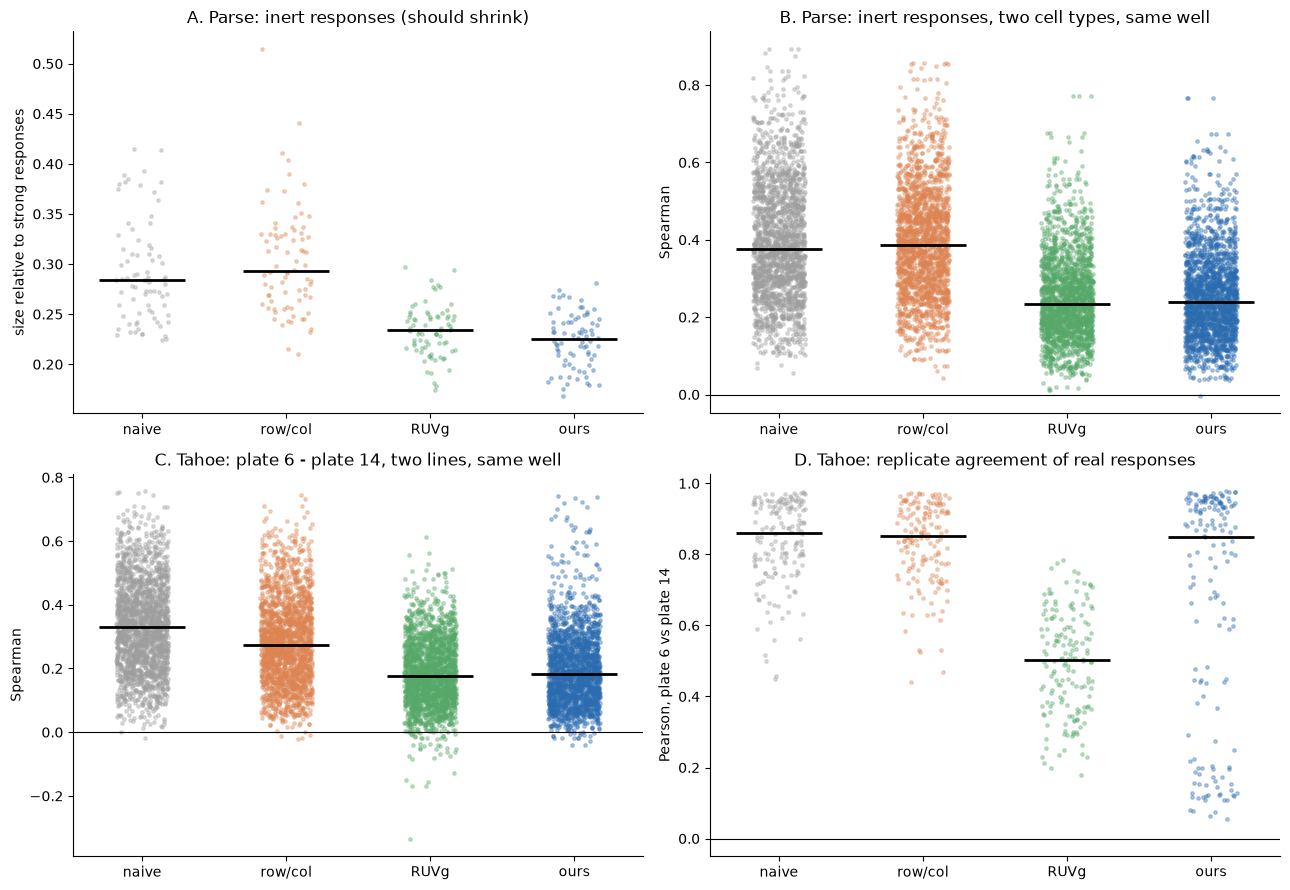

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_real_data/aim2_model_real_data.png True


In [13]:
COLM = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "ours": "#2b6cb0"}
METH = list(COLM)

def strip(a, data, title, ylab, ref=None):
    for i, m in enumerate(METH):
        v = data[m]; v = v[~np.isnan(v)]
        j = np.random.default_rng(SEED + i).uniform(-.18, .18, len(v))
        a.scatter(i + j, v, s=6, alpha=.35, color=COLM[m])
        a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
    if ref is not None:
        a.axhline(ref, color="k", lw=.8)
    a.set_xticks(range(len(METH))); a.set_xticklabels(METH)
    a.set_title(title); a.set_ylabel(ylab)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
strip(ax[0, 0], {m: PB_dist[m]["inert_rel"] for m in METH},
      "A. Parse: inert responses (should shrink)", "size relative to strong responses")
strip(ax[0, 1], {m: PB_dist[m]["same"] for m in METH},
      "B. Parse: inert responses, two cell types, same well", "Spearman", ref=0)
strip(ax[1, 0], {m: TD[m]["r_same"] for m in METH},
      "C. Tahoe: plate 6 - plate 14, two lines, same well", "Spearman", ref=0)
strip(ax[1, 1], {m: TD[m]["agree"] for m in METH},
      "D. Tahoe: replicate agreement of real responses", "Pearson, plate 6 vs plate 14", ref=0)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_model_real_data.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

## 11. Verdict

In [14]:
P, T = PARSE_RES, TAHOE_RES
best_base = lambda col, tab, low=True: (tab.loc[["naive", "row/col", "RUVg"], col].min() if low
                                        else tab.loc[["naive", "row/col", "RUVg"], col].max())
best_corr = lambda col, tab: tab.loc[["row/col", "RUVg"], col].max()   # best other correction
# Note: naive agreement is inflated by the well effect that repeats on every plate,
# so "kept" is judged against the other corrections, not against naive.
verdict = pd.DataFrame([
    ("Parse: inert responses smaller than naive", f"{P.loc['ours', 'inert_size_rel']:.2f} vs {P.loc['naive', 'inert_size_rel']:.2f}",
     P.loc["ours", "inert_size_rel"] < P.loc["naive", "inert_size_rel"]),
    ("Parse: fewer inert pairs called responsive", f"{P.loc['ours', 'inert_called']:.2f} vs {P.loc['naive', 'inert_called']:.2f}",
     P.loc["ours", "inert_called"] < P.loc["naive", "inert_called"]),
    ("Parse: shared shift reduced", f"{P.loc['ours', 'shared_shift_rel']:.2f} vs {P.loc['naive', 'shared_shift_rel']:.2f}",
     P.loc["ours", "shared_shift_rel"] < P.loc["naive", "shared_shift_rel"]),
    ("Parse: Test B drops", f"{P.loc['ours', 'testB_same']:.2f} vs {P.loc['naive', 'testB_same']:.2f}",
     P.loc["ours", "testB_same"] < 0.5 * P.loc["naive", "testB_same"]),
    ("Parse: strong responses kept as well as other corrections", f"{P.loc['ours', 'top_half_agreement']:.2f} vs {best_corr('top_half_agreement', P):.2f}",
     P.loc["ours", "top_half_agreement"] >= 0.95 * best_corr("top_half_agreement", P)),
    ("Tahoe: Test R drops", f"{T.loc['ours', 'testR_same']:.2f} vs {T.loc['naive', 'testR_same']:.2f}",
     T.loc["ours", "testR_same"] < 0.5 * T.loc["naive", "testR_same"]),
    ("Tahoe: technical similarity drops", f"{T.loc['ours', 'tech_same']:.2f} vs {T.loc['naive', 'tech_same']:.2f}",
     T.loc["ours", "tech_same"] < T.loc["naive", "tech_same"]),
    ("Tahoe: replicate agreement kept as well as other corrections", f"{T.loc['ours', 'replicate_agreement']:.2f} vs {best_corr('replicate_agreement', T):.2f}",
     T.loc["ours", "replicate_agreement"] >= 0.95 * best_corr("replicate_agreement", T)),
    ("Ours best on Parse inert size", f"best baseline {best_base('inert_size_rel', P):.2f}",
     P.loc["ours", "inert_size_rel"] <= best_base("inert_size_rel", P)),
    ("Ours best on Tahoe Test R", f"best baseline {best_base('testR_same', T):.2f}",
     T.loc["ours", "testR_same"] <= best_base("testR_same", T)),
], columns=["check", "value", "passes"])
verdict.to_csv(os.path.join(OUT_DIR, "verdict.csv"), index=False)
print(verdict.to_string(index=False))
stamp(T_START, "whole notebook")

                                                       check              value  passes
                   Parse: inert responses smaller than naive       0.22 vs 0.28    True
                  Parse: fewer inert pairs called responsive       0.01 vs 0.03    True
                                 Parse: shared shift reduced       0.11 vs 0.15    True
                                         Parse: Test B drops       0.24 vs 0.38   False
   Parse: strong responses kept as well as other corrections       0.92 vs 0.91    True
                                         Tahoe: Test R drops       0.18 vs 0.33   False
                           Tahoe: technical similarity drops       0.42 vs 0.57    True
Tahoe: replicate agreement kept as well as other corrections       0.85 vs 0.85    True
                               Ours best on Parse inert size best baseline 0.23    True
                                   Ours best on Tahoe Test R best baseline 0.18   False
[whole notebook] 177.3s | total 

## 12. Model v2: full-rank well signature
The rank test (section 9) shows that adding factors barely helps: the shared well effect is not low rank. The feasibility Test D suggests the right form: each well has its own **gene-level signature**, and each cell type sees it with its own per-gene slope:

$$W_{dkc} = b_c \odot s_{dk}, \qquad s_{dk}^{(-c)} = \text{mean of the non-responding cell types of well } (d,k) \text{ other than } c.$$

The signature for cell type *c* is computed **without c itself** (leave-one-out), and the slopes $b_c$ are fitted per gene across wells, as in Test D. The responder masks are the same as for the low-rank model, so only the model form changes.

For the pair tests (Test B, Test R, technical similarity), the correction of cell type *a* also excludes the partner *b*, so that no shared noise can create or remove correlation.

In [15]:
def m_signature(Y, nr, ridge=1e-2):
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0 = np.empty_like(Y)
    for d in range(D):
        for c in range(Cn):
            m = ok[d, :, c]
            Y0[d, :, c] = Y[d, :, c] - (Y[d, m, c].mean(0) if m.any() else np.nanmean(Y[d, :, c], 0))
    Y0z = np.nan_to_num(Y0)
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf                       # [D,K,C]
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    P[n_other == 0] = 0
    w = okf[..., None]
    B = (w * P * Y0z).sum((0, 1)) / ((w * P * P).sum((0, 1)) + ridge)   # [C,G] per-gene slopes
    Y1 = Y0z - B[None, None] * P
    Y1[~obs] = np.nan
    info = dict(Y0=Y0z, ok=ok, B=B, Y1=Y1)
    return Y1, info


def sig_pair(info, d, k, a, b):
    """Corrected values of a and b in well (d,k), each using a signature without a and b."""
    m = info["ok"][d, k].copy(); m[a] = m[b] = False
    if not m.any():
        return None
    s = info["Y0"][d, k, m].mean(0)
    return info["Y0"][d, k, a] - info["B"][a] * s, info["Y0"][d, k, b] - info["B"][b] * s


t0 = time.time()
PARSE["ours v2"], P_SIG = m_signature(YP, P_NR)
TAHOE["ours v2"] = (m_signature(YT[pa], T_NRA)[0], m_signature(YT[pb_], T_NRB)[0])
T_SIG = (m_signature(YT[pa], T_NRA)[1], m_signature(YT[pb_], T_NRB)[1])
stamp(t0, "model v2 fitted")

[model v2 fitted] 0.3s | total 3.0 min


In [16]:
t0 = time.time()
# ---- Parse checks for v2 (same definitions as section 5; pair tests exclude the partner)
Y1 = PARSE["ours v2"]
diff = contrast(Y1, P_CTRL)
tau = np.nanmean(diff, 0)
size = np.linalg.norm(tau, axis=-1)
sc, thr = calls_donors(Y1, P_CTRL)
pbs_mean = np.nanmean(Y1[:, P_CTRL], 1)                          # [D,C,G]
rng = np.random.default_rng(SEED)
inert_units = [(d, k) for d in range(len(DONORS)) for k in np.where(P_INERT)[0]]
same, dif = [], []
while len(same) < N_PAIRS:
    (d, k), (d2, k2) = [inert_units[i] for i in rng.choice(len(inert_units), 2, replace=False)]
    a, b = rng.choice(len(CELL_TYPES), 2, replace=False)
    pr = sig_pair(P_SIG, d, k, a, b)
    if pr is None or np.isnan(Y1[d, k, a, 0] + Y1[d, k, b, 0] + Y1[d2, k2, b, 0]):
        continue
    same.append(spearmanr(pr[0] - pbs_mean[d, a], pr[1] - pbs_mean[d, b])[0])
    dif.append(spearmanr(Y1[d, k, a] - pbs_mean[d, a], Y1[d2, k2, b] - pbs_mean[d2, b])[0])
same, dif = np.array(same), np.array(dif)
t1, t2 = np.nanmean(diff[H1], 0), np.nanmean(diff[H2], 0)
agree = np.array([np.corrcoef(t1[k, c], t2[k, c])[0, 1] for k, c in TOP])
PB_dist["ours v2"] = dict(inert_rel=(size[P_INERT] / REF).ravel(), same=same, agree=agree)
PARSE_RES.loc["ours v2"] = dict(
    inert_size_rel=np.nanmedian(size[P_INERT] / REF), inert_called=np.nanmean(sc[P_INERT] > thr),
    shared_shift_rel=np.mean([np.linalg.norm(np.nanmean(tau[P_INERT, c], 0)) for c in range(len(CELL_TYPES))]) / REF,
    testB_same=np.median(same), testB_diff=np.median(dif),
    top_half_agreement=np.nanmedian(agree), top_size_vs_naive=np.median([size[k, c] for k, c in TOP]) / REF)

# ---- Tahoe checks for v2
A, B = TAHOE["ours v2"]
ra, rb = contrast(A, T_CTRL)[0], contrast(B, T_CTRL)[0]
dm = ra - rb
center = np.nanmean(dm[~T_CTRL], 0)                               # per line, over wells
ctrl_a, ctrl_b = np.nanmean(A[0, T_CTRL], 0), np.nanmean(B[0, T_CTRL], 0)
rng = np.random.default_rng(SEED)
r_same, r_diff, t_same, t_diff, tries = [], [], [], [], 0
while (len(r_same) < N_PAIRS or len(t_same) < N_PAIRS) and tries < 400 * N_PAIRS:
    tries += 1
    u, v = rng.choice(ok_wells, 2, replace=False)
    a, b = rng.choice(len(LINES), 2, replace=False)
    pa_ = sig_pair(T_SIG[0], 0, u, a, b); pb2 = sig_pair(T_SIG[1], 0, u, a, b)
    if pa_ is None or pb2 is None or np.isnan(ra[u, a, 0] + ra[u, b, 0] + ra[v, b, 0] + rb[u, a, 0] + rb[u, b, 0] + rb[v, b, 0]):
        continue
    xa = (pa_[0] - ctrl_a[a]) - (pb2[0] - ctrl_b[a]) - center[a]
    xb = (pa_[1] - ctrl_a[b]) - (pb2[1] - ctrl_b[b]) - center[b]
    if len(r_same) < N_PAIRS:
        r_same.append(spearmanr(xa, xb)[0]); r_diff.append(spearmanr(dm[u, a] - center[a], dm[v, b] - center[b])[0])
    if len(t_same) < N_PAIRS and NR_BOTH[u, a] and NR_BOTH[u, b] and NR_BOTH[v, b]:
        t_same.append(spearmanr(pa_[0] - ctrl_a[a], pa_[1] - ctrl_a[b])[0]); t_diff.append(spearmanr(ra[u, a], ra[v, b])[0])
ks, cs = np.where(RESP_BOTH)
agree = np.array([np.corrcoef(ra[k, c], rb[k, c])[0, 1] for k, c in zip(ks, cs) if not np.isnan(ra[k, c, 0] + rb[k, c, 0])])
TD["ours v2"] = dict(r_same=np.array(r_same), agree=agree)
TAHOE_RES.loc["ours v2"] = dict(testR_same=np.median(r_same), testR_diff=np.median(r_diff),
                                tech_same=np.median(t_same), tech_diff=np.median(t_diff),
                                replicate_agreement=np.median(agree), n_resp_pairs=len(agree))
PARSE_RES.to_csv(os.path.join(OUT_DIR, "parse_checks.csv")); TAHOE_RES.to_csv(os.path.join(OUT_DIR, "tahoe_checks.csv"))
print("Parse"); print(PARSE_RES.round(3).to_string())
print("\nTahoe"); print(TAHOE_RES.round(3).to_string())
stamp(t0, "model v2 checks")

Parse
         inert_size_rel  inert_called  shared_shift_rel  testB_same  testB_diff  top_half_agreement  top_size_vs_naive
method                                                                                                                
naive             0.284         0.026             0.150       0.377       0.058               0.872              1.000
row/col           0.293         0.064             0.159       0.387       0.067               0.913              0.838
RUVg              0.234         0.051             0.109       0.235       0.033               0.838              0.584
ours              0.225         0.013             0.111       0.239       0.038               0.916              0.698
ours v2           0.142         0.064             0.072       0.105       0.003               0.876              0.701

Tahoe
         testR_same  testR_diff  tech_same  tech_diff  replicate_agreement  n_resp_pairs
method                                                           

## 13. Why do some Tahoe responses lose replicate agreement?
In panel D the low-rank model has a group of responder pairs with agreement below 0.5. If these sit in wells where most cell lines respond (few internal controls), the problem is the responder mask, not the model.

In [17]:
t0 = time.time()
ks, cs = np.where(RESP_BOTH)
rows = []
for name in ["ours", "ours v2"]:
    A, B = TAHOE[name]
    ra, rb = contrast(A, T_CTRL)[0], contrast(B, T_CTRL)[0]
    for k, c in zip(ks, cs):
        if np.isnan(ra[k, c, 0] + rb[k, c, 0]):
            continue
        rows.append(dict(method=name, well=WELLS[k], drug=drug[pa].get(WELLS[k]), line=LINES[c],
                         agreement=np.corrcoef(ra[k, c], rb[k, c])[0, 1],
                         controls_in_well=int(T_NRA[k].sum() + T_NRB[k].sum()) / 2))
DIAG = pd.DataFrame(rows)
DIAG["low"] = DIAG.agreement < 0.5
print(DIAG.groupby(["method", "low"]).controls_in_well.agg(["count", "median", "min", "max"]).round(1).to_string())
print("\nWells with the most low-agreement pairs (low-rank model):")
print(DIAG[(DIAG.method == "ours") & DIAG.low].groupby(["well", "drug"]).size().sort_values(ascending=False).head(10).to_string())
DIAG.to_csv(os.path.join(OUT_DIR, "tahoe_low_agreement.csv"), index=False)
stamp(t0, "diagnosis")

               count  median  min   max
method  low                            
ours    False    110     0.0  0.0  44.0
        True      52     3.0  0.0  44.0
ours v2 False    110     0.0  0.0  40.5
        True      52     3.0  0.0  44.0

Wells with the most low-agreement pairs (low-rank model):
well  drug                      
H3    Selinexor                     42
E6    Lidocaine (hydrochloride)      5
F3    Tucidinostat                   2
A7    Vinblastine (sulfate)          1
C12   Idarubicin (hydrochloride)     1
G1    Homoharringtonine              1
[diagnosis] 0.0s | total 3.0 min


## 14. Figure: low-rank model vs v2
Same four panels as section 10, with the v2 model added.

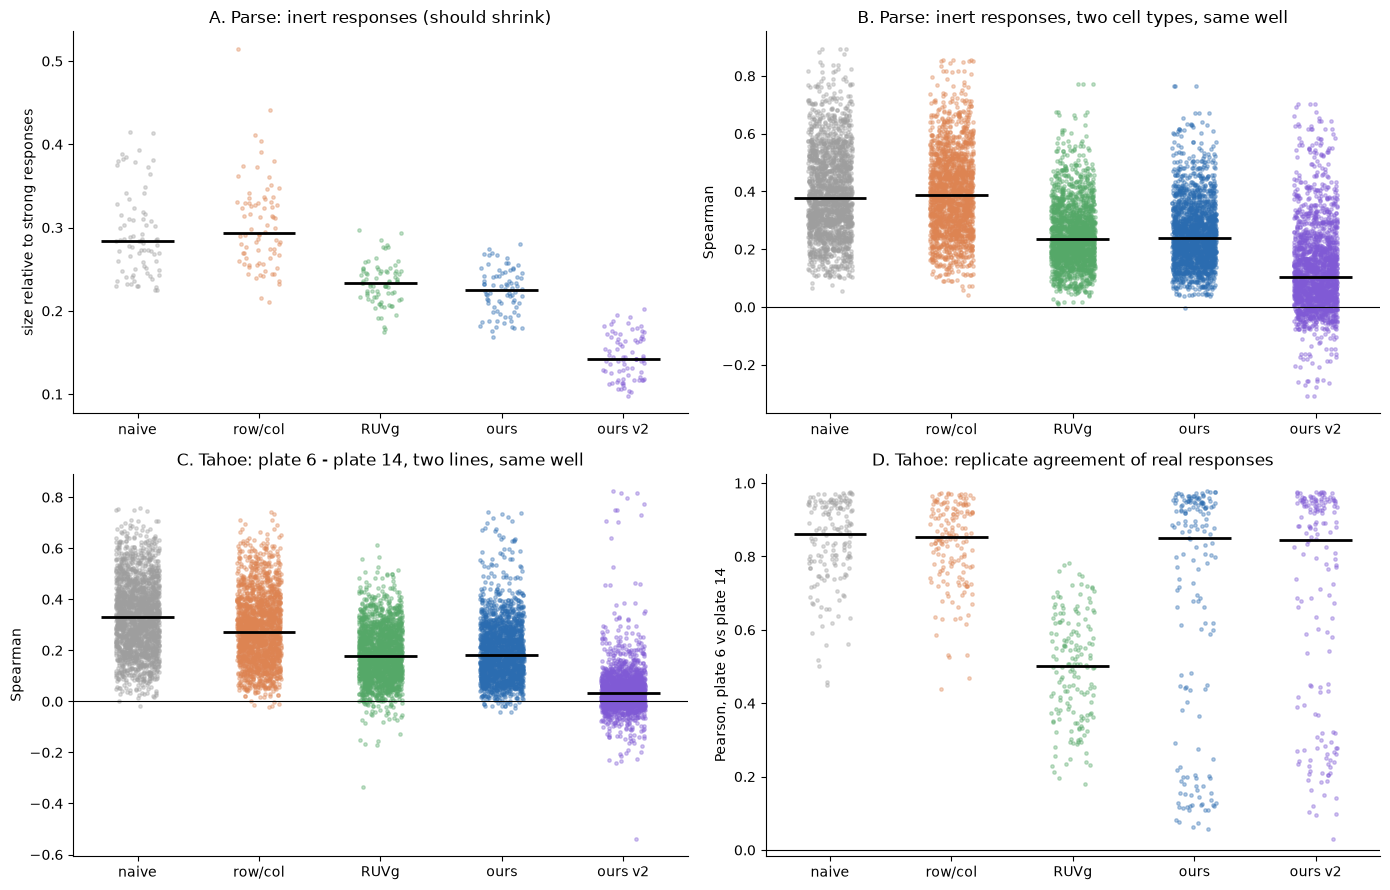

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_real_data/aim2_model_real_data_v2.png True
[whole notebook] 189.3s | total 3.2 min


In [18]:
COLM = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "ours": "#2b6cb0", "ours v2": "#805ad5"}
METH = list(COLM)
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
strip(ax[0, 0], {m: PB_dist[m]["inert_rel"] for m in METH},
      "A. Parse: inert responses (should shrink)", "size relative to strong responses")
strip(ax[0, 1], {m: PB_dist[m]["same"] for m in METH},
      "B. Parse: inert responses, two cell types, same well", "Spearman", ref=0)
strip(ax[1, 0], {m: TD[m]["r_same"] for m in METH},
      "C. Tahoe: plate 6 - plate 14, two lines, same well", "Spearman", ref=0)
strip(ax[1, 1], {m: TD[m]["agree"] for m in METH},
      "D. Tahoe: replicate agreement of real responses", "Pearson, plate 6 vs plate 14", ref=0)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_model_real_data_v2.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))
stamp(T_START, "whole notebook")

## 15. Final model: v2 correction with a control flag
* **Responders come from the low-rank model** (sections 4 and 7). It is the more stable caller: in a test on simulated data, re-calling responders with v2 itself let a responder's signal leak into the signature of the other cell types of its well, and the calls inflated. As a diagnostic we still print what v2 itself would call, but we do not use it.
* **Correction with v2** (full well signature).
* **Flag instead of guess.** A (well, cell type) entry is corrected only if the well has at least `MIN_CONTROLS` other non-responding cell types. Otherwise the entry is flagged and left out (NaN), and reported. In the simulation and in Tahoe (Selinexor, H3), wells with few internal controls were where the correction failed.

All methods are then compared on the same pairs: those that the final model does not flag.

In [19]:
MIN_CONTROLS = {"parse": 2, "tahoe": 5}   # about 10% of the cell lines in Tahoe; 2 of 6 cell types in Parse


def flag(Y1, info, min_ctrl):
    ok = info["ok"]
    n_other = ok.sum(-1)[..., None] - ok
    fl = n_other < min_ctrl
    Y1f = Y1.copy(); Y1f[fl] = np.nan
    return Y1f, fl


def discover_donors_sig(Y, is_ctrl, init_nr, rounds=3):
    nr = init_nr.copy()
    for _ in range(rounds):
        Y1, _ = m_signature(Y, nr)
        sc, thr = calls_donors(Y1, is_ctrl)
        nr = ~(sc > thr); nr[is_ctrl] = True
    Y1, info = m_signature(Y, nr)
    return Y1, info, nr


def crossfit_sig(Ya, Yb, is_ctrl, rounds=2):
    sa, sb = plate_score(Ya[0], is_ctrl), plate_score(Yb[0], is_ctrl)
    for _ in range(rounds):
        nra, nrb = nr_rule(sb, is_ctrl), nr_rule(sa, is_ctrl)
        (Ya1, ia), (Yb1, ib) = m_signature(Ya, nra), m_signature(Yb, nrb)
        sa, sb = plate_score(Ya1[0], is_ctrl), plate_score(Yb1[0], is_ctrl)
    return (Ya1, ia, nra), (Yb1, ib, nrb)


t0 = time.time()
Y1, F_PINFO = m_signature(YP, P_NR)
PARSE["final"], P_FLAG = flag(Y1, F_PINFO, MIN_CONTROLS["parse"])
F_NRA, F_NRB = T_NRA, T_NRB
(A, F_TA), (B, F_TB) = m_signature(YT[pa], F_NRA), m_signature(YT[pb_], F_NRB)
A, FLA = flag(A, F_TA, MIN_CONTROLS["tahoe"]); B, FLB = flag(B, F_TB, MIN_CONTROLS["tahoe"])
TAHOE["final"] = (A, B)
stamp(t0, "final model fitted")
print(f"Parse: flagged entries {P_FLAG[:, active].mean():.1%} | "
      f"Tahoe: flagged entries {FLA[0, ~T_CTRL].mean():.1%}, {FLB[0, ~T_CTRL].mean():.1%}")
fw = np.where((FLA[0] | FLB[0]).any(1))[0]
print("Tahoe flagged wells (well, drug, controls plate 6, controls plate 14):",
      [(WELLS[k], drug[pa].get(WELLS[k]), int(F_NRA[k].sum()), int(F_NRB[k].sum())) for k in fw])

# diagnostic only: what v2 itself would call as responders
t0 = time.time()
_, _, nr_p = discover_donors_sig(YP, P_CTRL, init_nr=P_NR)
(_, _, nr_a), (_, _, nr_b) = crossfit_sig(YT[pa], YT[pb_], T_CTRL)
print(f"Diagnostic, responders called by v2 itself: Parse {(~nr_p[active]).mean():.1%} (low-rank {(~P_NR[active]).mean():.1%}), "
      f"inert {(~nr_p[P_INERT]).mean():.1%} | Tahoe {(~nr_a[~T_CTRL]).mean():.1%}, {(~nr_b[~T_CTRL]).mean():.1%} "
      f"(low-rank {(~T_NRA[~T_CTRL]).mean():.1%}, {(~T_NRB[~T_CTRL]).mean():.1%})")
stamp(t0, "diagnostic")

[final model fitted] 0.2s | total 3.2 min
Parse: flagged entries 0.5% | Tahoe: flagged entries 4.3%, 4.3%
Tahoe flagged wells (well, drug, controls plate 6, controls plate 14): [('B11', 'L-Thyroxine (sodium salt pentahydrate)', 4, 48), ('C12', 'Idarubicin (hydrochloride)', 0, 0), ('G1', 'Homoharringtonine', 0, 0), ('H3', 'Selinexor ', 4, 2)]
Diagnostic, responders called by v2 itself: Parse 24.6% (low-rank 6.1%), inert 6.4% | Tahoe 9.6%, 9.0% (low-rank 9.4%, 7.8%)
[diagnostic] 3.6s | total 3.2 min


In [20]:
t0 = time.time()
# ---- Parse checks (pair tests exclude the partner)
def parse_checks_sig(Y1, info):
    diff = contrast(Y1, P_CTRL)
    tau = np.nanmean(diff, 0)
    size = np.linalg.norm(tau, axis=-1)
    sc, thr = calls_donors(Y1, P_CTRL)
    pbs_mean = np.nanmean(Y1[:, P_CTRL], 1)
    rng = np.random.default_rng(SEED)
    units = [(d, k) for d in range(len(DONORS)) for k in np.where(P_INERT)[0]]
    same, dif, tries = [], [], 0
    while len(same) < N_PAIRS and tries < 100 * N_PAIRS:
        tries += 1
        (d, k), (d2, k2) = [units[i] for i in rng.choice(len(units), 2, replace=False)]
        a, b = rng.choice(len(CELL_TYPES), 2, replace=False)
        pr = sig_pair(info, d, k, a, b)
        if pr is None or np.isnan(Y1[d, k, a, 0] + Y1[d, k, b, 0] + Y1[d2, k2, b, 0]):
            continue
        same.append(spearmanr(pr[0] - pbs_mean[d, a], pr[1] - pbs_mean[d, b])[0])
        dif.append(spearmanr(Y1[d, k, a] - pbs_mean[d, a], Y1[d2, k2, b] - pbs_mean[d2, b])[0])
    t1, t2 = np.nanmean(diff[H1], 0), np.nanmean(diff[H2], 0)
    agree = np.array([np.corrcoef(t1[k, c], t2[k, c])[0, 1] for k, c in TOP if not np.isnan(t1[k, c, 0] + t2[k, c, 0])])
    dist = dict(inert_rel=(size[P_INERT] / REF).ravel(), same=np.array(same), agree=agree)
    row = dict(inert_size_rel=np.nanmedian(size[P_INERT] / REF), inert_called=np.nanmean(sc[P_INERT] > thr),
               shared_shift_rel=np.mean([np.linalg.norm(np.nanmean(tau[P_INERT, c], 0)) for c in range(len(CELL_TYPES))]) / REF,
               testB_same=np.median(same), testB_diff=np.median(dif),
               top_half_agreement=np.nanmedian(agree), top_size_vs_naive=np.nanmedian([size[k, c] for k, c in TOP]) / REF)
    return row, dist, thr

row, PB_dist["final"], thr_final = parse_checks_sig(PARSE["final"], F_PINFO)
PARSE_RES.loc["final"] = row
print("PBS-vs-PBS threshold per method (higher = stricter calls):",
      {m: round(float(calls_donors(Y1, P_CTRL)[1]), 2) for m, Y1 in PARSE.items()})

# ---- Tahoe checks; replicate agreement on the pairs the final model keeps, for every method
A, B = TAHOE["final"]
ra, rb = contrast(A, T_CTRL)[0], contrast(B, T_CTRL)[0]
dm = ra - rb
center = np.nanmean(dm[~T_CTRL], 0)
ctrl_a, ctrl_b = np.nanmean(A[0, T_CTRL], 0), np.nanmean(B[0, T_CTRL], 0)
rng = np.random.default_rng(SEED)
r_same, r_diff, t_same, t_diff, tries = [], [], [], [], 0
while (len(r_same) < N_PAIRS or len(t_same) < N_PAIRS) and tries < 400 * N_PAIRS:
    tries += 1
    u, v = rng.choice(ok_wells, 2, replace=False)
    a, b = rng.choice(len(LINES), 2, replace=False)
    p1, p2 = sig_pair(F_TA, 0, u, a, b), sig_pair(F_TB, 0, u, a, b)
    if p1 is None or p2 is None or np.isnan(ra[u, a, 0] + ra[u, b, 0] + ra[v, b, 0] + rb[u, a, 0] + rb[u, b, 0] + rb[v, b, 0]):
        continue
    xa = (p1[0] - ctrl_a[a]) - (p2[0] - ctrl_b[a]) - center[a]
    xb = (p1[1] - ctrl_a[b]) - (p2[1] - ctrl_b[b]) - center[b]
    if len(r_same) < N_PAIRS:
        r_same.append(spearmanr(xa, xb)[0]); r_diff.append(spearmanr(dm[u, a] - center[a], dm[v, b] - center[b])[0])
    if len(t_same) < N_PAIRS and NR_BOTH[u, a] and NR_BOTH[u, b] and NR_BOTH[v, b]:
        t_same.append(spearmanr(p1[0] - ctrl_a[a], p1[1] - ctrl_a[b])[0]); t_diff.append(spearmanr(ra[u, a], ra[v, b])[0])

ks, cs = np.where(RESP_BOTH)
KEEP = [(k, c) for k, c in zip(ks, cs) if not np.isnan(ra[k, c, 0] + rb[k, c, 0])]
TD["final"] = dict(r_same=np.array(r_same))
TAHOE_RES.loc["final"] = dict(testR_same=np.median(r_same), testR_diff=np.median(r_diff),
                              tech_same=np.median(t_same), tech_diff=np.median(t_diff))
for m, (Am, Bm) in TAHOE.items():
    xa, xb = contrast(Am, T_CTRL)[0], contrast(Bm, T_CTRL)[0]
    ag = np.array([np.corrcoef(xa[k, c], xb[k, c])[0, 1] for k, c in KEEP if not np.isnan(xa[k, c, 0] + xb[k, c, 0])])
    TD[m]["agree_keep"] = ag
    TAHOE_RES.loc[m, "agreement_unflagged"] = np.median(ag)
TAHOE_RES.loc["final", "n_resp_pairs"] = len(KEEP)
PARSE_RES.to_csv(os.path.join(OUT_DIR, "parse_checks.csv")); TAHOE_RES.to_csv(os.path.join(OUT_DIR, "tahoe_checks.csv"))
print("\nParse"); print(PARSE_RES.round(3).to_string())
print("\nTahoe (agreement_unflagged: the same", len(KEEP), "responder pairs for every method)")
print(TAHOE_RES.round(3).to_string())
stamp(t0, "final checks")

PBS-vs-PBS threshold per method (higher = stricter calls): {'naive': 19.41, 'row/col': 19.29, 'RUVg': 11.99, 'ours': 15.6, 'ours v2': 4.01, 'final': 4.01}

Parse
         inert_size_rel  inert_called  shared_shift_rel  testB_same  testB_diff  top_half_agreement  top_size_vs_naive
method                                                                                                                
naive             0.284         0.026             0.150       0.377       0.058               0.872              1.000
row/col           0.293         0.064             0.159       0.387       0.067               0.913              0.838
RUVg              0.234         0.051             0.109       0.235       0.033               0.838              0.584
ours              0.225         0.013             0.111       0.239       0.038               0.916              0.698
ours v2           0.142         0.064             0.072       0.105       0.003               0.876              0.701
final

## 16. Final figure and verdict
Methods: naive, row/col, RUVg, the low-rank model, and the final model. Panel D uses the same responder pairs for every method (those the final model does not flag).

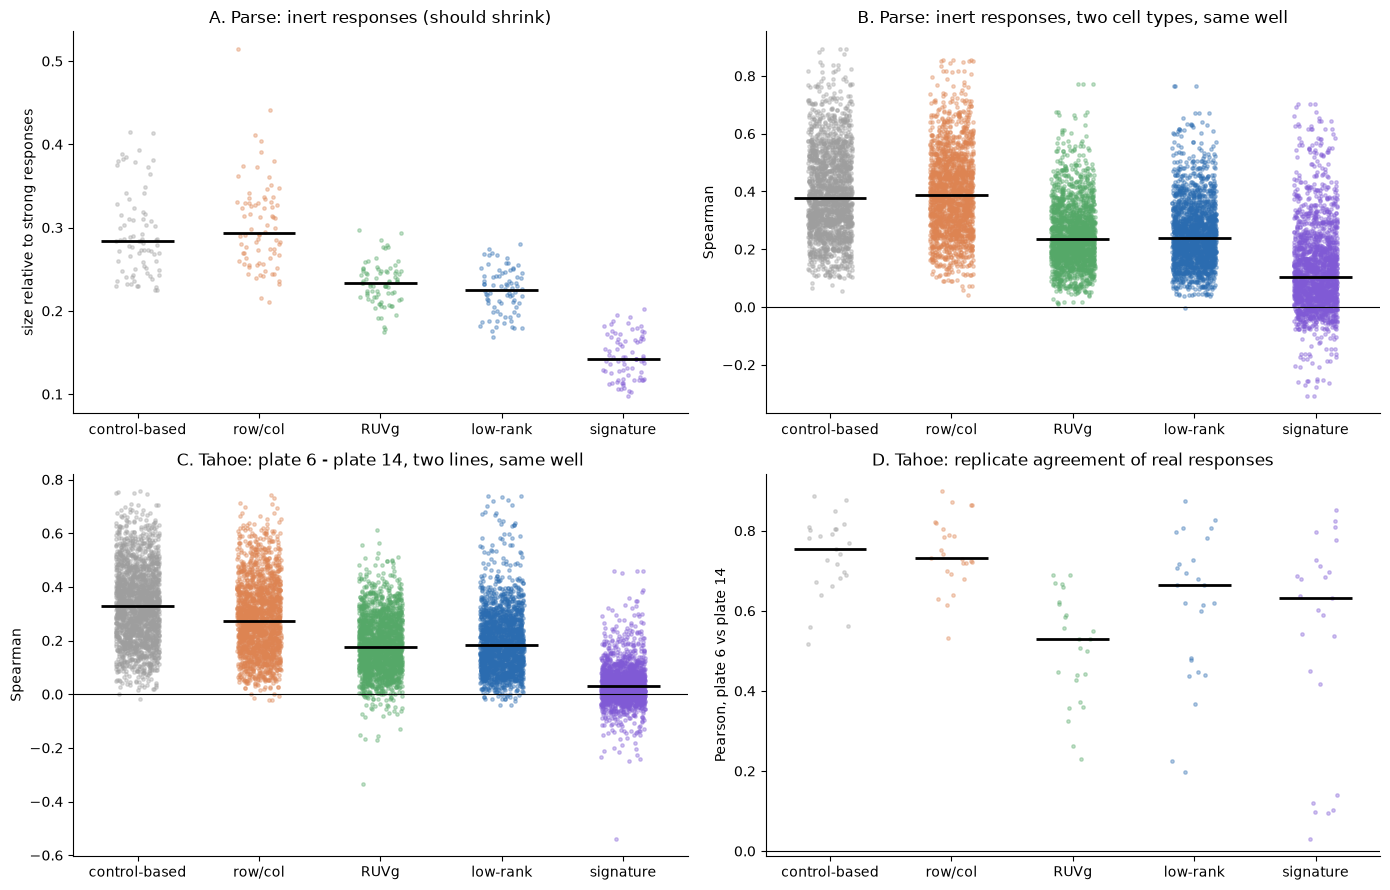

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_real_data/real_data.png True
                                       check                   value  passes
             Parse: smallest inert responses 0.14 vs best other 0.22    True
                      Parse: smallest Test B 0.11 vs best other 0.23    True
                Parse: strong responses kept      0.87 vs naive 0.87    True
                      Tahoe: smallest Test R 0.03 vs best other 0.18    True
         Tahoe: technical similarity removed      0.01 vs naive 0.57    True
Tahoe: replicate agreement kept (same pairs)      0.63 vs naive 0.75   False
[whole notebook] 4737.9s | total 79.0 min


In [33]:
COLM = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "ours": "#2b6cb0", "final": "#805ad5"}
METH = list(COLM)
LABEL = {"ours": "low-rank", "final": "final (v2)"}
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
strip(ax[0, 0], {m: PB_dist[m]["inert_rel"] for m in METH},
      "A. Parse: inert responses (should shrink)", "size relative to strong responses")
strip(ax[0, 1], {m: PB_dist[m]["same"] for m in METH},
      "B. Parse: inert responses, two cell types, same well", "Spearman", ref=0)
strip(ax[1, 0], {m: TD[m]["r_same"] for m in METH},
      "C. Tahoe: plate 6 - plate 14, two lines, same well", "Spearman", ref=0)
strip(ax[1, 1], {m: TD[m]["agree_keep"] for m in METH},
      "D. Tahoe: replicate agreement of real responses", "Pearson, plate 6 vs plate 14", ref=0)
for a in ax.ravel():
    a.set_xticklabels([LABEL.get(m, m) for m in METH])
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "real_data.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank", "two-part": "signature, two-part"}

def rename_labels(fig, mapping=RENAME):
    sub = lambda s: mapping.get(s, s)
    legends = list(fig.legends) + [a.get_legend() for a in fig.axes if a.get_legend()]
    for leg in legends:
        for t in leg.get_texts():
            t.set_text(sub(t.get_text()))
    for a in fig.axes:
        a.set_xticklabels([sub(t.get_text()) for t in a.get_xticklabels()])
        for t in a.texts:
            t.set_text(sub(t.get_text()))
        a.set_ylabel(a.get_ylabel().replace("naive", "control-based"))

rename_labels(fig)
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

P, T = PARSE_RES, TAHOE_RES
others = ["naive", "row/col", "RUVg", "ours"]
verdict = pd.DataFrame([
    ("Parse: smallest inert responses", f"{P.loc['final', 'inert_size_rel']:.2f} vs best other {P.loc[others, 'inert_size_rel'].min():.2f}",
     P.loc["final", "inert_size_rel"] <= P.loc[others, "inert_size_rel"].min()),
    ("Parse: smallest Test B", f"{P.loc['final', 'testB_same']:.2f} vs best other {P.loc[others, 'testB_same'].min():.2f}",
     P.loc["final", "testB_same"] <= P.loc[others, "testB_same"].min()),
    ("Parse: strong responses kept", f"{P.loc['final', 'top_half_agreement']:.2f} vs naive {P.loc['naive', 'top_half_agreement']:.2f}",
     P.loc["final", "top_half_agreement"] >= 0.95 * P.loc["naive", "top_half_agreement"]),
    ("Tahoe: smallest Test R", f"{T.loc['final', 'testR_same']:.2f} vs best other {T.loc[others, 'testR_same'].min():.2f}",
     T.loc["final", "testR_same"] <= T.loc[others, "testR_same"].min()),
    ("Tahoe: technical similarity removed", f"{T.loc['final', 'tech_same']:.2f} vs naive {T.loc['naive', 'tech_same']:.2f}",
     T.loc["final", "tech_same"] < 0.25 * T.loc["naive", "tech_same"]),
    ("Tahoe: replicate agreement kept (same pairs)", f"{T.loc['final', 'agreement_unflagged']:.2f} vs naive {T.loc['naive', 'agreement_unflagged']:.2f}",
     T.loc["final", "agreement_unflagged"] >= 0.95 * T.loc["naive", "agreement_unflagged"]),
], columns=["check", "value", "passes"])
verdict.to_csv(os.path.join(OUT_DIR, "verdict_final.csv"), index=False)
print(verdict.to_string(index=False))
stamp(T_START, "whole notebook")

## 17. Independent tests of preserved biology
The technical checks show that the shared signal is removed, but not that it was technical. These two tests use responder masks that do **not** come from the expression data.

* **Tahoe, genotype-targeted drugs.** A drug that targets a mutant gene (for example KRAS, BRAF or EGFR) should act mainly on the cell lines that carry a driver mutation in that gene. For each such drug, carriers should have larger responses than non-carriers. Score: AUROC of response size, carriers vs non-carriers (0.5 = no separation). A good correction keeps or raises the AUROC.
* **Parse, receptor expression.** A cytokine cannot act directly on a cell type that lacks its receptor. Receptor-positive (cytokine, cell type) pairs should have larger responses than receptor-negative ones. Score: AUROC as above. Receptor-negative pairs that still respond after correction are candidates for paracrine signalling.

Edit `TAHOE_META` if the metadata folder is elsewhere. The cell prints the metadata columns it uses; check them.

In [22]:
import re
from scipy.stats import mannwhitneyu
TAHOE_META = "data/tahoe100m_metadata/metadata"
COMPARE = ["naive", "row/col", "RUVg", "ours", "final"]

def auroc(pos, neg):
    pos, neg = np.asarray(pos, float), np.asarray(neg, float)
    pos, neg = pos[~np.isnan(pos)], neg[~np.isnan(neg)]
    if len(pos) < 2 or len(neg) < 2:
        return np.nan
    return mannwhitneyu(pos, neg, alternative="two-sided").statistic / (len(pos) * len(neg))

t0 = time.time()
DM = pd.read_parquet(os.path.join(TAHOE_META, "drug_metadata.parquet"))
CL = pd.read_parquet(os.path.join(TAHOE_META, "cell_line_metadata.parquet"))
print("drug_metadata columns:", DM.columns.tolist())
print("cell_line_metadata columns:", CL.columns.tolist())
col = lambda df, keys: next((c for c in df.columns if any(k in c.lower() for k in keys)), None)
DRUG_COL, TARGET_COL = col(DM, ["drug"]), col(DM, ["target"])
LINE_NAME_COL = "cell_name" if "cell_name" in CL.columns else col(CL, ["cell_name", "name"])
GENE_COL = col(CL, ["driver_gene", "gene_symbol", "gene"])
print(f"Using: drug={DRUG_COL}, targets={TARGET_COL}, line={LINE_NAME_COL}, driver gene={GENE_COL}")

split = lambda x: {g.strip().upper() for g in re.split(r"[,;|/ ]+", str(x)) if g.strip()}
drv = CL.groupby(CL[LINE_NAME_COL].astype(str))[GENE_COL].apply(lambda s: {str(g).upper() for g in s if pd.notna(g)})
driver_genes = set().union(*drv.values)
tgt = DM.set_index(DM[DRUG_COL].astype(str).str.strip())[TARGET_COL].apply(split)

rows = []
for k, w in enumerate(WELLS):
    if T_CTRL[k]:
        continue
    d = str(drug[pa].get(w, "")).strip()
    genes_t = tgt.get(d, set()) & driver_genes
    if not genes_t:
        continue
    carrier = np.array([bool(drv.get(l, set()) & genes_t) for l in LINES])
    if carrier.sum() < 2 or (~carrier).sum() < 2:
        continue
    row = dict(well=w, drug=d, target_genes=",".join(sorted(genes_t)),
               n_carriers=int(carrier.sum()), flagged=bool((FLA[0, k] | FLB[0, k]).any()))
    for m in COMPARE:
        A, B = TAHOE[m]
        ra, rb = contrast(A, T_CTRL)[0][k], contrast(B, T_CTRL)[0][k]
        size = (np.linalg.norm(ra, axis=-1) + np.linalg.norm(rb, axis=-1)) / 2
        row[m] = auroc(size[carrier], size[~carrier])
    rows.append(row)
GENO = pd.DataFrame(rows)
GENO.to_csv(os.path.join(OUT_DIR, "test_genotype_drugs.csv"), index=False)
if len(GENO):
    print(GENO.round(3).to_string(index=False))
    print("\nMedian AUROC (unflagged wells):", GENO[~GENO.flagged][COMPARE].median().round(3).to_dict())
else:
    print("No genotype-targeted drug with >= 2 carriers and >= 2 non-carriers on these plates.")
stamp(t0, "genotype test")

drug_metadata columns: ['drug', 'targets', 'moa-broad', 'moa-fine', 'human-approved', 'clinical-trials', 'gpt-notes-approval', 'canonical_smiles', 'pubchem_cid']
cell_line_metadata columns: ['cell_name', 'Cell_ID_DepMap', 'Cell_ID_Cellosaur', 'Organ', 'Driver_Gene_Symbol', 'Driver_VarZyg', 'Driver_VarType', 'Driver_ProtEffect_or_CdnaEffect', 'Driver_Mech_InferDM', 'Driver_GeneType_DM']
Using: drug=drug, targets=targets, line=cell_name, driver gene=Driver_Gene_Symbol
well                         drug target_genes  n_carriers  flagged  naive  row/col  RUVg  ours  final
  B8                 Temsirolimus         MTOR           2    False  0.446    0.391 0.467 0.446  0.446
  C3                  Tofacitinib         JAK1           2    False  0.413    0.380 0.413 0.391  0.576
  D3                    Rapamycin         MTOR           2    False  0.489    0.380 0.533 0.413  0.457
  D5        Tofacitinib (citrate)         JAK1           2    False  0.435    0.554 0.413 0.446  0.576
  D7 Almonerti

In [23]:
# Parse: receptor mask. Required subunits per cytokine ("any" = at least one subunit).
RECEPTORS = {
    "ifngamma": ["IFNGR1", "IFNGR2"], "ifnbeta": ["IFNAR1", "IFNAR2"], "ifnalpha": ["IFNAR1", "IFNAR2"],
    "ifnomega": ["IFNAR1", "IFNAR2"], "ifnlambda1": ["IFNLR1", "IL10RB"], "ifnlambda2": ["IFNLR1", "IL10RB"],
    "ifnlambda3": ["IFNLR1", "IL10RB"], "il2": ["IL2RB", "IL2RG"], "il15": ["IL2RB", "IL2RG"],
    "il4": ["IL4R"], "il13": ["IL13RA1", "IL4R"], "il7": ["IL7R", "IL2RG"], "il21": ["IL21R", "IL2RG"],
    "il6": ["IL6R", "IL6ST"], "il10": ["IL10RA", "IL10RB"], "il12": ["IL12RB1", "IL12RB2"],
    "il18": ["IL18R1", "IL18RAP"], "il1beta": ["IL1R1", "IL1RAP"], "gmcsf": ["CSF2RA", "CSF2RB"],
    "mcsf": ["CSF1R"], "il3": ["IL3RA", "CSF2RB"], "il5": ["IL5RA", "CSF2RB"], "il27": ["IL27RA", "IL6ST"],
    "il17a": ["IL17RA", "IL17RC"], "tslp": ["CRLF2", "IL7R"], "tnfalpha": ("any", ["TNFRSF1A", "TNFRSF1B"]),
}
RECEPTOR_CPM = 5.0          # mean CPM in PBS wells needed to call a subunit expressed
norm = lambda x: re.sub(r"[^a-z0-9]", "", str(x).lower())

t0 = time.time()
vn = pd.Index(pb.var_names.astype(str))
need = sorted({g for v in RECEPTORS.values() for g in (v[1] if isinstance(v, tuple) else v)} & set(vn))
cpm_r = to_cpm(pb[o.index].X)[:, [vn.get_loc(g) for g in need]].toarray()
pbs_rows = (o.cytokine.values == "PBS") & (o.n_cells.values >= MIN_CELLS)
expr = pd.DataFrame({c: cpm_r[pbs_rows & (o.ct.values == c)].mean(0) for c in CELL_TYPES}, index=need)

rows, paracrine = [], []
for k, cy in enumerate(CYT):
    rule = RECEPTORS.get(norm(cy))
    if rule is None:
        continue
    mode, genes_r = rule if isinstance(rule, tuple) else ("all", rule)
    genes_r = [g for g in genes_r if g in expr.index]
    if not genes_r:
        continue
    for c, ctn in enumerate(CELL_TYPES):
        v = expr.loc[genes_r, ctn]
        pos = (v.max() if mode == "any" else v.min()) >= RECEPTOR_CPM
        rows.append(dict(well=WELLS[k], cytokine=cy, cell_type=ctn, receptor_pos=pos, k=k, c=c))
REC = pd.DataFrame(rows)
print(f"Cytokines matched: {REC.cytokine.nunique()} | pairs: {len(REC)} | receptor-negative: {(~REC.receptor_pos).sum()}")
if (~REC.receptor_pos).sum() == 0:
    print("No receptor-negative pairs at RECEPTOR_CPM; lower it or extend RECEPTORS. AUROC will be NaN.")

res = {}
for m in COMPARE:
    tau = np.nanmean(contrast(PARSE[m], P_CTRL), 0)
    size = np.linalg.norm(tau, axis=-1)
    s = size[REC.k.values, REC.c.values]
    res[m] = auroc(s[REC.receptor_pos.values], s[~REC.receptor_pos.values])
    inert95 = np.nanquantile(size[P_INERT], 0.95)
    for (_, r), v in zip(REC.iterrows(), s):
        if not r.receptor_pos and v > inert95:
            paracrine.append(dict(method=m, cytokine=r.cytokine, cell_type=r.cell_type, size_vs_inert95=v / inert95))
REC_RES = pd.Series(res, name="AUROC receptor-positive vs negative")
PARA = pd.DataFrame(paracrine)
REC.to_csv(os.path.join(OUT_DIR, "test_receptor_pairs.csv"), index=False)
PARA.to_csv(os.path.join(OUT_DIR, "test_receptor_paracrine_candidates.csv"), index=False)
print(REC_RES.round(3).to_string())
if len(PARA):
    print("\nReceptor-negative pairs above the 95th percentile of inert responses (paracrine candidates):")
    print(PARA.groupby("method").size().to_string())
    print(PARA[PARA.method == "final"].sort_values("size_vs_inert95", ascending=False).head(10).round(2).to_string(index=False))
stamp(t0, "receptor test")

Cytokines matched: 24 | pairs: 144 | receptor-negative: 51
naive      0.729
row/col    0.713
RUVg       0.742
ours       0.674
final      0.726

Receptor-negative pairs above the 95th percentile of inert responses (paracrine candidates):
method
RUVg       16
final      31
naive      29
ours       22
row/col    26
method  cytokine cell_type  size_vs_inert95
 final      IL-2 CD14 Mono             3.71
 final      IL-2 CD16 Mono             3.58
 final     IL-15 CD14 Mono             3.54
 final     IL-15 CD16 Mono             3.47
 final IL-1-beta CD16 Mono             2.64
 final     IL-12 CD16 Mono             2.17
 final     IL-12 CD14 Mono             2.02
 final IFN-gamma        NK             1.92
 final IL-1-beta         B             1.80
 final IL-1-beta        NK             1.79
[receptor test] 0.8s | total 3.4 min


## 18. How wide would the bounds be?
Bounds for a flagged well need a prediction of its signature from wells that are not flagged. Before writing them, we measure how well such predictions work in unflagged wells, where the signature is known. Predictors:

* **row/col**: additive row and column means of the other unflagged wells of the same plate (Tahoe) or donor plate (Parse);
* **same well, other plate**: the signature of the same position on another plate with a different drug (Tahoe plate 13); in Parse, the mean signature of the same well in the other donors (the layout is identical).

Per-gene slopes are fitted on half of the wells and tested on the other half (as in Test D). The relative bound width is the 95th percentile of the prediction error divided by the median signature size; a value near or above 1 means the bounds would be as wide as the effect itself.

In [24]:
def signatures(info):
    ok, Y0 = info["ok"], info["Y0"]
    n = ok.sum(-1)
    S = np.einsum("dkc,dkcg->dkg", ok.astype(np.float32), Y0) / np.maximum(n, 1)[..., None]
    S[n < 1] = np.nan
    return S, n

def heldout(Yv, X, seed=SEED):
    """Yv, X [n, G]. Per-gene slope fitted on one half, R2 and error norms on the other half."""
    m = ~(np.isnan(Yv).any(1) | np.isnan(X).any(1))
    idx = np.where(m)[0]
    rng = np.random.default_rng(seed); rng.shuffle(idx)
    h = [idx[: len(idx) // 2], idx[len(idx) // 2:]]
    num = den = 0.0; err = []
    for a, b in [(0, 1), (1, 0)]:
        beta = (X[h[a]] * Yv[h[a]]).sum(0) / ((X[h[a]] ** 2).sum(0) + 1e-9)
        r = Yv[h[b]] - beta * X[h[b]]
        num += (r ** 2).sum(); den += (Yv[h[b]] ** 2).sum(); err.extend(np.linalg.norm(r, axis=1))
    width = np.quantile(err, 0.95) / np.median(np.linalg.norm(Yv[idx], axis=1))
    return 1 - num / den, width, len(idx)

def rowcol_pred(S, keep):
    """S [K,G] one plate; additive row + column prediction from other kept wells."""
    P = np.full_like(S, np.nan)
    for k in range(96):
        o_ = keep.copy(); o_[k] = False
        rmean = np.nanmean(S[o_ & (ROW == ROW[k])], 0); cmean = np.nanmean(S[o_ & (COL == COL[k])], 0)
        P[k] = rmean + cmean - np.nanmean(S[o_], 0)
    return P

t0 = time.time()
rows = []
# Tahoe plate 6 (final model), unflagged wells
S6, n6 = signatures(F_TA)
keep6 = (n6[0] >= MIN_CONTROLS["tahoe"]) & ~T_CTRL
Yv = np.where(keep6[:, None], S6[0], np.nan)
r2, wd, n = heldout(Yv, rowcol_pred(S6[0], keep6))
rows.append(dict(data="Tahoe plate 6", predictor="row/col, same plate", heldout_R2=r2, rel_bound_width=wd, n_wells=n))

# Tahoe plate 13 (different drugs, same positions): build it like plates 6 and 14
p13 = "plate13"
if os.path.exists(os.path.join(TAHOE_DIR, f"pseudobulk_{p13}.h5ad")):
    b13 = ad.read_h5ad(os.path.join(TAHOE_DIR, f"pseudobulk_{p13}.h5ad"))
    ob = b13.obs.copy(); ob["sample"] = ob["sample"].astype(str); ob["line"] = ob["line"].astype(str)
    ob["well"] = ob["sample"].map(wmap[wmap.plate == p13].set_index("sample").well)
    cp13 = to_cpm(b13.X)[:, tgenes].toarray()
    Y13 = np.full((1, 96, len(LINES), N_GENES), np.nan, np.float32)
    for kk, (w, l, nn) in enumerate(zip(ob.well, ob.line, ob.n_cells)):
        if l in li and nn >= MIN_CELLS and w in wi:
            Y13[0, wi[w], li[l]] = np.log2(cp13[kk] + 1)
    ctrl13 = np.array([str(wmap[(wmap.plate == p13) & (wmap.well == w)].drug.squeeze()) == "DMSO_TF" for w in WELLS])
    nr13 = nr_rule(plate_score(Y13[0], ctrl13), ctrl13)          # own plate: no replicate to cross-fit
    S13, n13 = signatures(m_signature(Y13, nr13)[1])
    keep13 = keep6 & (n13[0] >= MIN_CONTROLS["tahoe"]) & ~ctrl13
    r2, wd, n = heldout(np.where(keep13[:, None], S6[0], np.nan), np.where(keep13[:, None], S13[0], np.nan))
    rows.append(dict(data="Tahoe plate 6", predictor="same well, plate 13", heldout_R2=r2, rel_bound_width=wd, n_wells=n))

# Parse (final model): row/col within donor, and same well in the other donors
SP, nP = signatures(F_PINFO)
keepP = nP >= MIN_CONTROLS["parse"]
Yv_all, Xrc_all, Xod_all = [], [], []
for d in range(len(DONORS)):
    Yv_all.append(np.where(keepP[d][:, None], SP[d], np.nan))
    Xrc_all.append(rowcol_pred(SP[d], keepP[d]))
    others = [e for e in range(len(DONORS)) if e != d]
    Xod_all.append(np.nanmean(np.where(keepP[others][..., None], SP[others], np.nan), 0))
Yv_all, Xrc_all, Xod_all = map(np.vstack, (Yv_all, Xrc_all, Xod_all))
for name, X in [("row/col, same donor plate", Xrc_all), ("same well, other donors", Xod_all)]:
    r2, wd, n = heldout(Yv_all, X)
    rows.append(dict(data="Parse", predictor=name, heldout_R2=r2, rel_bound_width=wd, n_wells=n))
BOUND = pd.DataFrame(rows)
BOUND.to_csv(os.path.join(OUT_DIR, "bound_pretest.csv"), index=False)
print(BOUND.round(3).to_string(index=False))
stamp(t0, "bound pre-test")

         data                 predictor  heldout_R2  rel_bound_width  n_wells
Tahoe plate 6       row/col, same plate       0.054            1.363       90
Tahoe plate 6       same well, plate 13       0.340            1.257       87
        Parse row/col, same donor plate       0.018            2.570     1150
        Parse   same well, other donors       0.449            1.847     1150
[bound pre-test] 2.8s | total 3.5 min


## 19. Figure: independent tests and bound pre-test

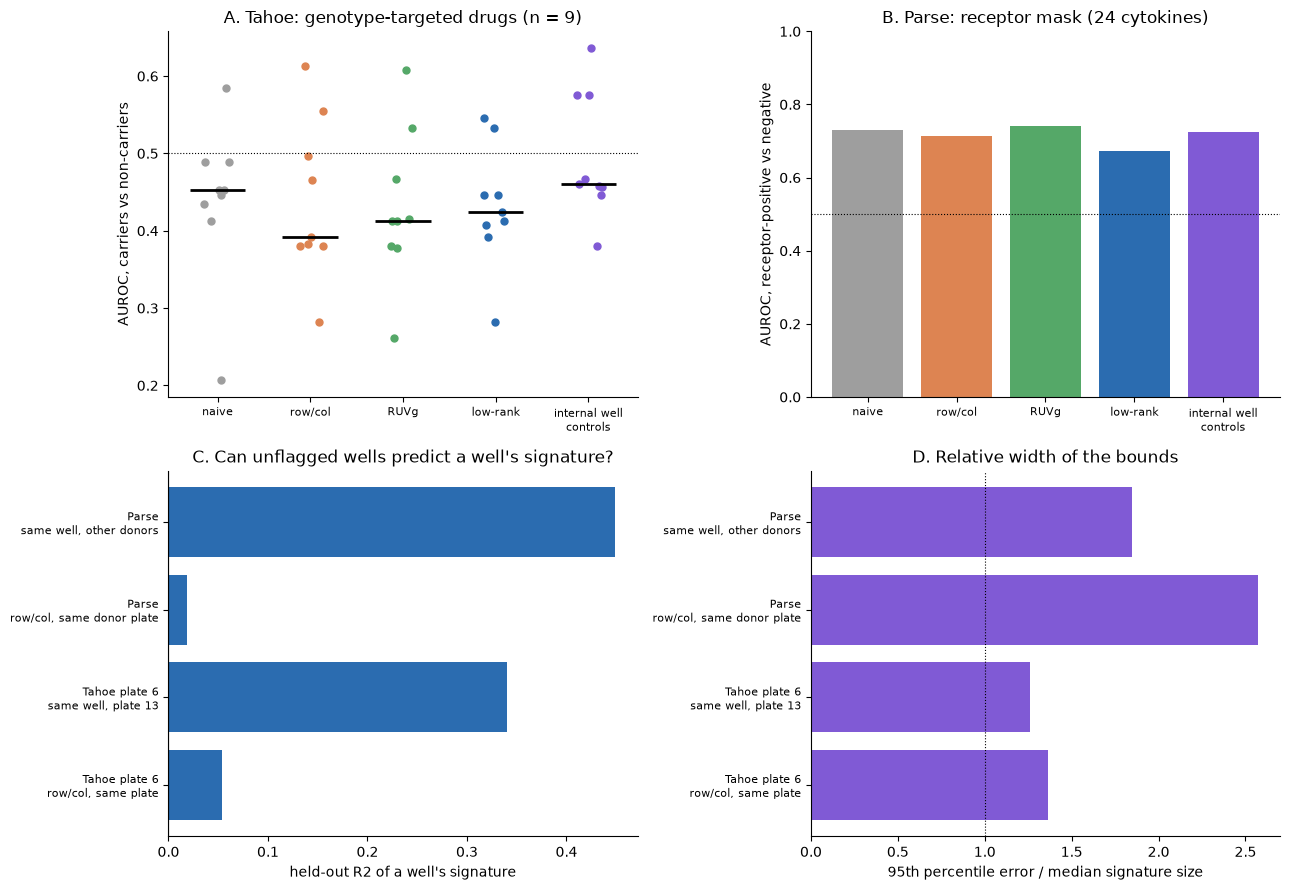

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_real_data/aim2_independent_tests.png True
[whole notebook] 220.3s | total 3.7 min


In [25]:
COLM2 = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "ours": "#2b6cb0", "final": "#805ad5"}
LAB2 = {"ours": "low-rank", "final": "internal well\ncontrols"}
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]
if len(GENO):
    G = GENO[~GENO.flagged]
    for i, m in enumerate(COMPARE):
        v = G[m].dropna().values
        a.scatter(i + np.random.default_rng(SEED + i).uniform(-.15, .15, len(v)), v, color=COLM2[m], s=25)
        if len(v): a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.axhline(0.5, color="k", lw=.8, ls=":")
a.set_xticks(range(len(COMPARE))); a.set_xticklabels([LAB2.get(m, m) for m in COMPARE], fontsize=8)
a.set_ylabel("AUROC, carriers vs non-carriers"); a.set_title(f"A. Tahoe: genotype-targeted drugs (n = {len(GENO[~GENO.flagged]) if len(GENO) else 0})")

a = ax[0, 1]
a.bar(range(len(COMPARE)), REC_RES[COMPARE].values, color=[COLM2[m] for m in COMPARE])
a.axhline(0.5, color="k", lw=.8, ls=":")
a.set_xticks(range(len(COMPARE))); a.set_xticklabels([LAB2.get(m, m) for m in COMPARE], fontsize=8)
a.set_ylim(0, 1); a.set_ylabel("AUROC, receptor-positive vs negative")
a.set_title(f"B. Parse: receptor mask ({REC.cytokine.nunique()} cytokines)")

a = ax[1, 0]
lab = BOUND.data + "\n" + BOUND.predictor
a.barh(range(len(BOUND)), BOUND.heldout_R2, color="#2b6cb0")
a.set_yticks(range(len(BOUND))); a.set_yticklabels(lab, fontsize=8); a.axvline(0, color="k", lw=.8)
a.set_xlabel("held-out R2 of a well's signature"); a.set_title("C. Can unflagged wells predict a well's signature?")

a = ax[1, 1]
a.barh(range(len(BOUND)), BOUND.rel_bound_width, color="#805ad5")
a.set_yticks(range(len(BOUND))); a.set_yticklabels(lab, fontsize=8); a.axvline(1, color="k", lw=.8, ls=":")
a.set_xlabel("95th percentile error / median signature size"); a.set_title("D. Relative width of the bounds")
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_independent_tests.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))
stamp(T_START, "whole notebook")

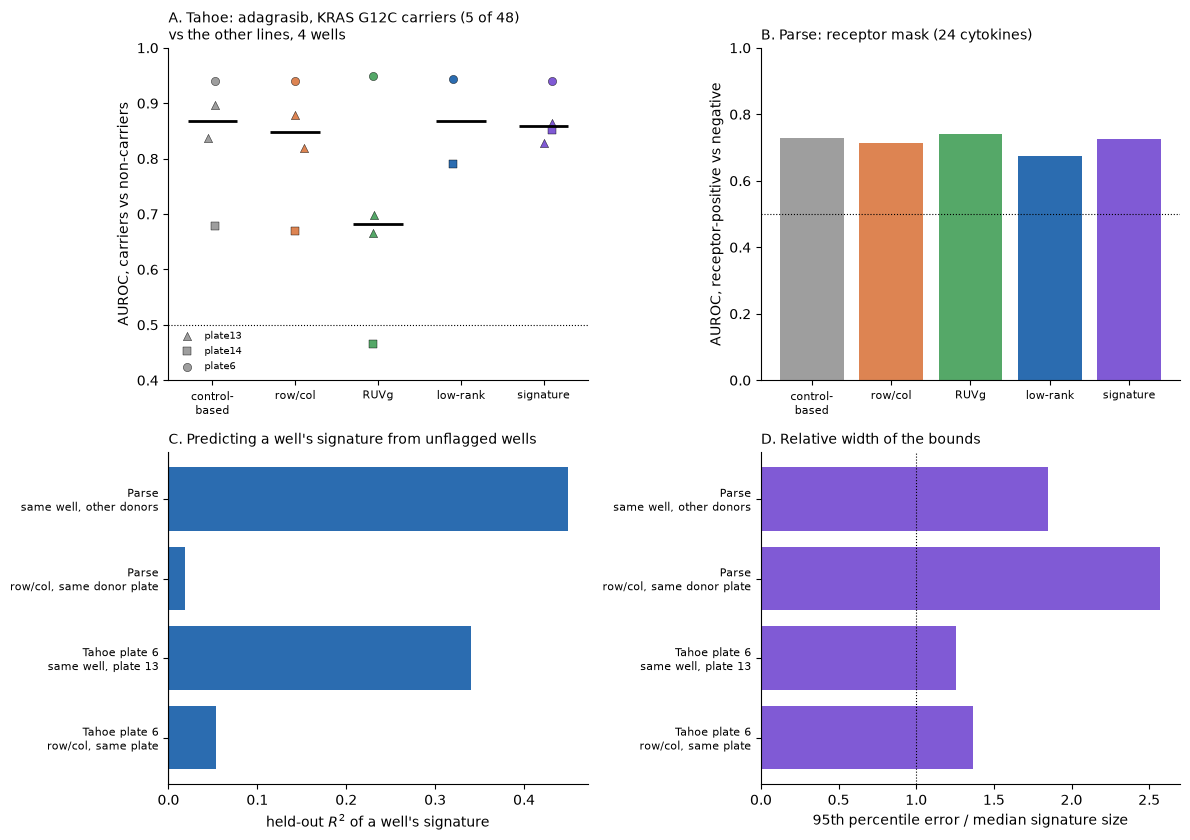

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_real_data/independent_tests.png
  plate well      drug  naive  row/col  RUVg  ours  final
 plate6  H10 Adagrasib  0.940    0.940 0.949 0.944  0.940
plate14  H10 Adagrasib  0.679    0.670 0.465 0.791  0.851
plate13   B9 Adagrasib  0.898    0.879 0.665   NaN  0.865
plate13  B10 Adagrasib  0.837    0.819 0.698   NaN  0.828


In [26]:
# Figure 4 of Paper 2 (independent_tests.png), panel A replaced by the variant-based genotype test.
# Stand-alone: reads the CSVs written by aim2_model_real_data.ipynb (sections 18 and 22); no kernel state needed.
# Method names as in the paper: control-based, row/col, RUVg, low-rank, signature.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = "results/cache/aim2_model_real_data"
SEED = 0
COMPARE = ["naive", "row/col", "RUVg", "ours", "final"]
LAB = {"naive": "control-\nbased", "row/col": "row/col", "RUVg": "RUVg", "ours": "low-rank", "final": "signature"}
COL = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "ours": "#2b6cb0", "final": "#805ad5"}

GENO2 = pd.read_csv(os.path.join(OUT_DIR, "test_genotype_variants.csv"))
BOUND = pd.read_csv(os.path.join(OUT_DIR, "bound_pretest.csv"))
# Receptor AUROCs of section 17 (printed there, not saved to CSV; the same values are in the paper)
REC_RES = pd.Series({"naive": 0.729, "row/col": 0.713, "RUVg": 0.742, "ours": 0.674, "final": 0.726})

fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
a = ax[0, 0]
mk = {"plate6": "o", "plate14": "s", "plate13": "^"}
for i, m in enumerate(COMPARE):
    for p, g in GENO2.groupby("plate"):
        v = g[m].dropna().values
        a.scatter(i + np.random.default_rng(SEED + i).uniform(-.12, .12, len(v)), v, color=COL[m], s=35,
                  marker=mk.get(p, "o"), edgecolor="k", lw=.3, label=p if i == 0 else None)
    v = GENO2[m].dropna().values
    if len(v):
        a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.axhline(0.5, color="k", lw=.8, ls=":")
a.set_ylim(0.4, 1.0)
a.set_xticks(range(len(COMPARE))); a.set_xticklabels([LAB[m] for m in COMPARE], fontsize=8)
a.set_ylabel("AUROC, carriers vs non-carriers")
a.set_title(f"A. Tahoe: adagrasib, KRAS G12C carriers ({int(GENO2.n_carriers.iloc[0])} of 48)\n"
            f"vs the other lines, {len(GENO2)} wells", loc="left", fontsize=10)
a.legend(frameon=False, fontsize=7, loc="lower left")

a = ax[0, 1]
a.bar(range(len(COMPARE)), REC_RES[COMPARE].values, color=[COL[m] for m in COMPARE])
a.axhline(0.5, color="k", lw=.8, ls=":")
a.set_xticks(range(len(COMPARE))); a.set_xticklabels([LAB[m] for m in COMPARE], fontsize=8)
a.set_ylim(0, 1); a.set_ylabel("AUROC, receptor-positive vs negative")
a.set_title("B. Parse: receptor mask (24 cytokines)", loc="left", fontsize=10)

lab = BOUND.data + "\n" + BOUND.predictor
a = ax[1, 0]
a.barh(range(len(BOUND)), BOUND.heldout_R2, color="#2b6cb0")
a.set_yticks(range(len(BOUND))); a.set_yticklabels(lab, fontsize=8); a.axvline(0, color="k", lw=.8)
a.set_xlabel("held-out $R^2$ of a well's signature")
a.set_title("C. Predicting a well's signature from unflagged wells", loc="left", fontsize=10)

a = ax[1, 1]
a.barh(range(len(BOUND)), BOUND.rel_bound_width, color="#805ad5")
a.set_yticks(range(len(BOUND))); a.set_yticklabels(lab, fontsize=8); a.axvline(1, color="k", lw=.8, ls=":")
a.set_xlabel("95th percentile error / median signature size")
a.set_title("D. Relative width of the bounds", loc="left", fontsize=10)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "independent_tests.png"))
fig.savefig(png, dpi=300); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)
print(GENO2[["plate", "well", "drug"] + COMPARE].round(3).to_string(index=False))

## 20. Two-part signature on Parse
In the second simulator, the two-part signature gave the lowest error: the part of a well's signature that is the same in every donor (the layout is identical) is averaged over donors before it is removed, and the donor-specific part is removed separately, each with its own per-gene slope. Responders come from the low-rank caller, as for the final model. Pair tests (Test B) exclude the partner from the signature, in every donor. Tahoe is not changed: its plates are corrected one at a time, so there is no donor axis to average over.

In [27]:
def m_signature2(Y, nr, ridge=1e-2):
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0 = np.empty_like(Y)
    for d in range(D):
        for c in range(Cn):
            m = ok[d, :, c]
            Y0[d, :, c] = Y[d, :, c] - (Y[d, m, c].mean(0) if m.any() else np.nanmean(Y[d, :, c], 0))
    Y0z = np.nan_to_num(Y0)
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    has = n_other > 0
    P[~has] = 0
    hw = has.astype(np.float32)[..., None]
    Pm = ((P * hw).sum(0) / np.maximum(hw.sum(0), 1))[None].repeat(D, 0)   # same position, mean over donors
    Pd = np.where(hw > 0, P - Pm, 0)                                         # donor-specific part
    w = okf[..., None]
    a11, a22, a12 = (w * Pm * Pm).sum((0, 1)) + ridge, (w * Pd * Pd).sum((0, 1)) + ridge, (w * Pm * Pd).sum((0, 1))
    b1, b2 = (w * Pm * Y0z).sum((0, 1)), (w * Pd * Y0z).sum((0, 1))
    det = a11 * a22 - a12 ** 2
    B1, B2 = (a22 * b1 - a12 * b2) / det, (a11 * b2 - a12 * b1) / det
    Y1 = Y0z - B1[None, None] * Pm - B2[None, None] * Pd
    Y1[~obs] = np.nan
    return Y1, dict(Y0=Y0z, ok=ok, B1=B1, B2=B2)


def sig2_pair(info, d, k, a, b):
    """Corrected a and b in well (d,k); every donor's signature at well k excludes a and b."""
    ok, Y0 = info["ok"], info["Y0"]
    s = []
    for e in range(ok.shape[0]):
        m = ok[e, k].copy(); m[a] = m[b] = False
        s.append(Y0[e, k, m].mean(0) if m.any() else None)
    if s[d] is None:
        return None
    sm = np.mean([v for v in s if v is not None], 0); sd = s[d] - sm
    fix = lambda c: Y0[d, k, c] - info["B1"][c] * sm - info["B2"][c] * sd
    return fix(a), fix(b)


def parse_checks_pairfun(Y1, pairfun):
    diff = contrast(Y1, P_CTRL)
    tau = np.nanmean(diff, 0)
    size = np.linalg.norm(tau, axis=-1)
    sc, thr = calls_donors(Y1, P_CTRL)
    pbs_mean = np.nanmean(Y1[:, P_CTRL], 1)
    rng = np.random.default_rng(SEED)
    units = [(d, k) for d in range(len(DONORS)) for k in np.where(P_INERT)[0]]
    same, dif, tries = [], [], 0
    while len(same) < N_PAIRS and tries < 100 * N_PAIRS:
        tries += 1
        (d, k), (d2, k2) = [units[i] for i in rng.choice(len(units), 2, replace=False)]
        a, b = rng.choice(len(CELL_TYPES), 2, replace=False)
        pr = pairfun(d, k, a, b)
        if pr is None or np.isnan(Y1[d, k, a, 0] + Y1[d, k, b, 0] + Y1[d2, k2, b, 0]):
            continue
        same.append(spearmanr(pr[0] - pbs_mean[d, a], pr[1] - pbs_mean[d, b])[0])
        dif.append(spearmanr(Y1[d, k, a] - pbs_mean[d, a], Y1[d2, k2, b] - pbs_mean[d2, b])[0])
    t1, t2 = np.nanmean(diff[H1], 0), np.nanmean(diff[H2], 0)
    agree = np.array([np.corrcoef(t1[k, c], t2[k, c])[0, 1] for k, c in TOP if not np.isnan(t1[k, c, 0] + t2[k, c, 0])])
    dist = dict(inert_rel=(size[P_INERT] / REF).ravel(), same=np.array(same), agree=agree)
    row = dict(inert_size_rel=np.nanmedian(size[P_INERT] / REF), inert_called=np.nanmean(sc[P_INERT] > thr),
               shared_shift_rel=np.mean([np.linalg.norm(np.nanmean(tau[P_INERT, c], 0)) for c in range(len(CELL_TYPES))]) / REF,
               testB_same=np.median(same), testB_diff=np.median(dif),
               top_half_agreement=np.nanmedian(agree), top_size_vs_naive=np.nanmedian([size[k, c] for k, c in TOP]) / REF)
    return row, dist


t0 = time.time()
Y1, F2_INFO = m_signature2(YP, P_NR)
PARSE["two-part"], P_FLAG2 = flag(Y1, F2_INFO, MIN_CONTROLS["parse"])
row, PB_dist["two-part"] = parse_checks_pairfun(PARSE["two-part"], lambda d, k, a, b: sig2_pair(F2_INFO, d, k, a, b))
PARSE_RES.loc["two-part"] = row
# receptor test for the two-part model
tau2 = np.nanmean(contrast(PARSE["two-part"], P_CTRL), 0)
s2 = np.linalg.norm(tau2, axis=-1)[REC.k.values, REC.c.values]
REC_RES["two-part"] = auroc(s2[REC.receptor_pos.values], s2[~REC.receptor_pos.values])
PARSE_RES.to_csv(os.path.join(OUT_DIR, "parse_checks.csv"))
print(PARSE_RES.loc[["naive", "RUVg", "ours", "final", "two-part"]].round(3).to_string())
print("\nReceptor AUROC:", REC_RES.round(3).to_dict())
stamp(t0, "two-part signature")

          inert_size_rel  inert_called  shared_shift_rel  testB_same  testB_diff  top_half_agreement  top_size_vs_naive
method                                                                                                                 
naive              0.284         0.026             0.150       0.377       0.058               0.872              1.000
RUVg               0.234         0.051             0.109       0.235       0.033               0.838              0.584
ours               0.225         0.013             0.111       0.239       0.038               0.916              0.698
final              0.142         0.064             0.072       0.105       0.003               0.866              0.701
two-part           0.141         0.090             0.071       0.069      -0.004               0.860              0.671

Receptor AUROC: {'naive': 0.729, 'row/col': 0.713, 'RUVg': 0.742, 'ours': 0.674, 'final': 0.726, 'two-part': 0.724}
[two-part signature] 1.8s | total 3.9 min


## 21. Calibrated response calls
With the PBS-vs-PBS null, a small error in the estimated signature of a position, repeated in every donor, can be called a response (the second simulator showed false calls of 0.41 to 0.71 for the signature models). Two calibrated nulls fixed this in simulation (two-part signature: false calls 0.04 with negative controls, 0.00 with the empirical null, true calls 1.00 and 0.98):

* **Negative controls**: 95th percentile of the scores of a random half of the inert cytokines (fixed seed). False calls are measured only on the other half.
* **Empirical** (no labels): median + 1.645 robust SD of the log scores of all non-control pairs.

Also reported: the share of positive controls (`TOP`) called, and the share of all other non-inert pairs called.

In [28]:
from scipy.stats import norm

def thr_empirical(sc, mask, q=0.95):
    v = np.log(sc[mask & ~np.isnan(sc)])
    med = np.median(v); mad = 1.4826 * np.median(np.abs(v - med))
    return float(np.exp(med + norm.ppf(q) * mad))

t0 = time.time()
inert_w = np.where(P_INERT)[0].copy()
np.random.default_rng(SEED).shuffle(inert_w)
CAL_W, EV_W = inert_w[: len(inert_w) // 2], inert_w[len(inert_w) // 2:]
other = active & ~P_INERT
rows = []
for m in ["naive", "row/col", "RUVg", "ours", "final", "two-part"]:
    sc, thr_p = calls_donors(PARSE[m], P_CTRL)
    v = sc[CAL_W].ravel(); thr_n = float(np.nanquantile(v, 0.95))
    thr_e = thr_empirical(sc, np.broadcast_to(active[:, None], sc.shape))
    for null, thr in [("PBS-vs-PBS", thr_p), ("negative controls", thr_n), ("empirical", thr_e)]:
        ev = sc[EV_W].ravel(); ev = ev[~np.isnan(ev)]
        top = np.array([sc[k, c] for k, c in TOP]); top = top[~np.isnan(top)]
        oth = sc[other].ravel(); oth = oth[~np.isnan(oth)]
        rows.append(dict(method=m, null=null, threshold=thr, false_calls_heldout_inert=np.mean(ev > thr),
                         positive_controls_called=np.mean(top > thr), other_pairs_called=np.mean(oth > thr)))
CALIB = pd.DataFrame(rows)
CALIB.to_csv(os.path.join(OUT_DIR, "parse_calibrated_calls.csv"), index=False)
print("Calibration half:", sorted(CYT[CAL_W]), "\nEvaluation half:", sorted(CYT[EV_W]))
print(CALIB.pivot(index="method", columns="null", values="false_calls_heldout_inert").round(3).to_string())
print("\nPositive controls called:")
print(CALIB.pivot(index="method", columns="null", values="positive_controls_called").round(3).to_string())
print("\nOther non-inert pairs called:")
print(CALIB.pivot(index="method", columns="null", values="other_pairs_called").round(3).to_string())
stamp(t0, "calibrated calls")

Calibration half: [np.str_('Decorin'), np.str_('HGF'), np.str_('IGF-1'), np.str_('PSPN'), np.str_('TPO'), np.str_('VEGF')] 
Evaluation half: [np.str_('EGF'), np.str_('EPO'), np.str_('FGF-beta'), np.str_('GDNF'), np.str_('Megalin'), np.str_('Noggin'), np.str_('PRL')]
null      PBS-vs-PBS  empirical  negative controls
method                                            
RUVg           0.071      0.000              0.071
final          0.071      0.024              0.095
naive          0.048      0.048              0.071
ours           0.000      0.000              0.071
row/col        0.095      0.048              0.167
two-part       0.095      0.000              0.071

Positive controls called:
null      PBS-vs-PBS  empirical  negative controls
method                                            
RUVg           1.000      0.875                1.0
final          1.000      1.000                1.0
naive          0.875      0.875                1.0
ours           0.875      0.750            

## 22. Genotype test with the targeted variants
The first genotype test counted any driver mutation in the target gene. Here a cell line counts as a carrier only if it carries the variant the drug is designed for (from `Driver_ProtEffect_or_CdnaEffect`):

| Drugs | Carriers |
|---|---|
| KRAS G12C inhibitors (adagrasib, sotorasib, divarasib) | KRAS G12C |
| KRAS G12D inhibitors (MRTX1133) | KRAS G12D |
| EGFR inhibitors | activating EGFR mutations (L858R, exon 19 deletions, T790M, G719X, L861Q, exon 20 insertions) |
| BRAF inhibitors (vemurafenib, dabrafenib, encorafenib) | BRAF V600 |
| MEK inhibitors (trametinib, cobimetinib, binimetinib, selumetinib, mirdametinib) | BRAF V600 or KRAS/NRAS/HRAS codon 12, 13 or 61 |
| PI3K-alpha inhibitors (alpelisib, inavolisib) | PIK3CA H1047, E545, E542 |

Plates 6 and 14 as before (all methods), plus plate 13 (different drugs; one plate, so methods that need a replicate plate are left out).

In [29]:
VARIANT_RULES = {
    "KRAS G12C": (["adagrasib", "sotorasib", "divarasib"], {"KRAS"}, r"G12C"),
    "KRAS G12D": (["mrtx1133"], {"KRAS"}, r"G12D"),
    "EGFR activating": (["osimertinib", "almonertinib", "erlotinib", "gefitinib", "afatinib", "dacomitinib",
                         "lazertinib", "furmonertinib", "icotinib", "aumolertinib", "befotertinib"],
                        {"EGFR"}, r"L858R|T790M|G719|L861Q|E746|L747|del|ins"),
    "BRAF V600": (["vemurafenib", "dabrafenib", "encorafenib"], {"BRAF"}, r"V600"),
    "MAPK active": (["trametinib", "cobimetinib", "binimetinib", "selumetinib", "mirdametinib"],
                    {"BRAF", "KRAS", "NRAS", "HRAS"}, r"V600|G12|G13|Q61"),
    "PIK3CA hotspot": (["alpelisib", "inavolisib"], {"PIK3CA"}, r"H1047|E545|E542"),
}
EFF_COL = col(CL, ["proteffect", "cdnaeffect", "effect"])
print("Variant column:", EFF_COL)
lines_var = {}
for l, g in CL[[LINE_NAME_COL, GENE_COL, EFF_COL]].astype(str).groupby(LINE_NAME_COL):
    lines_var[l] = list(zip(g[GENE_COL].str.upper(), g[EFF_COL]))

def carriers(rule):
    _, genes, rx = rule
    return np.array([any(gn in genes and re.search(rx, ef) for gn, ef in lines_var.get(l, [])) for l in LINES])

def rule_for(drugname):
    dn = drugname.lower()
    for name, rule in VARIANT_RULES.items():
        if any(x in dn for x in rule[0]):
            return name, rule
    return None, None

def size_of(R, k):
    return np.linalg.norm(R[k], axis=-1)

t0 = time.time()
rows = []
for p in REPLICATE:
    for k, w in enumerate(WELLS):
        if T_CTRL[k]:
            continue
        d = str(drug[p].get(w, "")); name, rule = rule_for(d)
        if rule is None:
            continue
        car = carriers(rule)
        if car.sum() < 2 or (~car).sum() < 2:
            continue
        row = dict(plate=p, well=w, drug=d, variant=name, n_carriers=int(car.sum()),
                   flagged=bool((FLA if p == pa else FLB)[0, k].any()))
        for m in COMPARE:
            R = contrast(TAHOE[m][0 if p == pa else 1], T_CTRL)[0]
            sz = size_of(R, k); row[m] = auroc(sz[car], sz[~car])
        rows.append(row)
# plate 13 (built in section 18)
if "Y13" in globals():
    corr13 = {"naive": Y13, "row/col": m_rowcol(Y13), "RUVg": m_ruvg(Y13),
              "final": flag(*m_signature(Y13, nr13), MIN_CONTROLS["tahoe"])[0]}
    drug13 = wmap[wmap.plate == "plate13"].set_index("well").drug.astype(str)
    for k, w in enumerate(WELLS):
        if ctrl13[k]:
            continue
        d = drug13.get(w, ""); name, rule = rule_for(d)
        if rule is None:
            continue
        car = carriers(rule)
        if car.sum() < 2 or (~car).sum() < 2:
            continue
        row = dict(plate="plate13", well=w, drug=d, variant=name, n_carriers=int(car.sum()), flagged=False)
        for m, Ym in corr13.items():
            sz = size_of(contrast(Ym, ctrl13)[0], k); row[m] = auroc(sz[car], sz[~car])
        rows.append(row)
GENO2 = pd.DataFrame(rows)
GENO2.to_csv(os.path.join(OUT_DIR, "test_genotype_variants.csv"), index=False)
if len(GENO2):
    print(GENO2.round(3).to_string(index=False))
    print("\nMedian AUROC:", GENO2[COMPARE].median().round(3).to_dict())
else:
    print("No drug with a targeted-variant rule and >= 2 carriers on these plates. Drugs on plates 6/14:")
    print(sorted(set(drug[pa].astype(str))))
stamp(t0, "variant genotype test")

Variant column: Driver_ProtEffect_or_CdnaEffect
  plate well      drug   variant  n_carriers  flagged  naive  row/col  RUVg  ours  final
 plate6  H10 Adagrasib KRAS G12C           5    False  0.940    0.940 0.949 0.944  0.940
plate14  H10 Adagrasib KRAS G12C           5    False  0.679    0.670 0.465 0.791  0.851
plate13   B9 Adagrasib KRAS G12C           5    False  0.898    0.898 0.665   NaN  0.865
plate13  B10 Adagrasib KRAS G12C           5    False  0.837    0.837 0.698   NaN  0.828

Median AUROC: {'naive': 0.867, 'row/col': 0.867, 'RUVg': 0.681, 'ours': 0.867, 'final': 0.858}
[variant genotype test] 0.7s | total 3.9 min


## 23. Figure: two-part signature, calibrated calls, variant genotype test

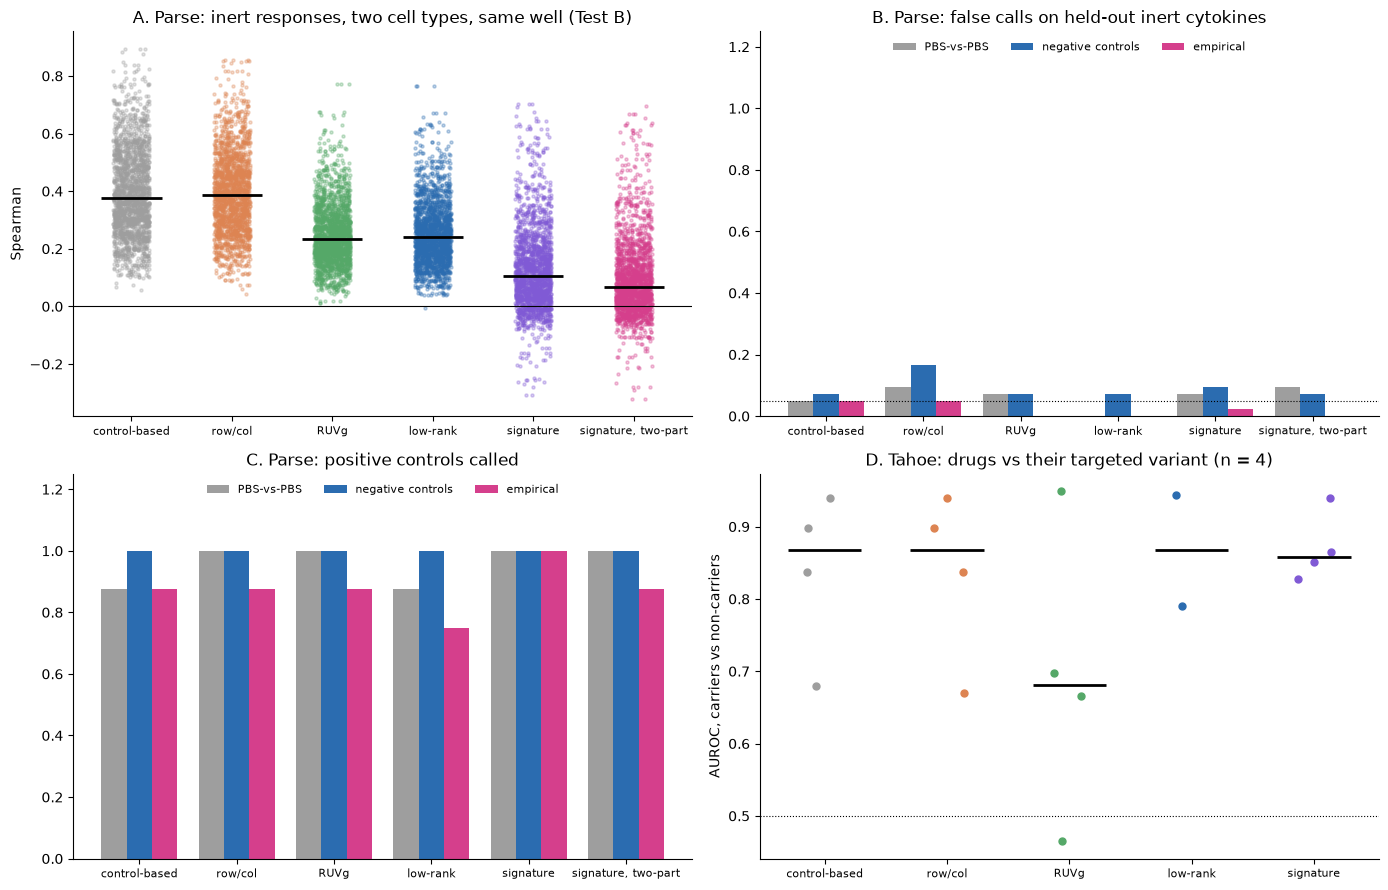

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_real_data/aim2_two_part_calibration_variants.png True
[whole notebook] 4958.9s | total 82.6 min


In [35]:
MS = ["naive", "row/col", "RUVg", "ours", "final", "two-part"]
CM = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "ours": "#2b6cb0", "final": "#805ad5", "two-part": "#d53f8c"}
LB = {"ours": "low-rank", "final": "signature", "two-part": "signature, two-part"}
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
a = ax[0, 0]
for i, m in enumerate(MS):
    v = PB_dist[m]["same"]; v = v[~np.isnan(v)]
    a.scatter(i + np.random.default_rng(SEED + i).uniform(-.18, .18, len(v)), v, s=5, alpha=.3, color=CM[m])
    a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.axhline(0, color="k", lw=.8)
a.set_xticks(range(len(MS))); a.set_xticklabels([LB.get(m, m) for m in MS], fontsize=8)
a.set_ylabel("Spearman"); a.set_title("A. Parse: inert responses, two cell types, same well (Test B)")

NULLS = ["PBS-vs-PBS", "negative controls", "empirical"]
NC = {"PBS-vs-PBS": "#9e9e9e", "negative controls": "#2b6cb0", "empirical": "#d53f8c"}
x = np.arange(len(MS)); w = 0.26
for j, (metric, title) in enumerate([("false_calls_heldout_inert", "B. Parse: false calls on held-out inert cytokines"),
                                     ("positive_controls_called", "C. Parse: positive controls called")]):
    a = ax[0, 1] if j == 0 else ax[1, 0]
    for i, nl in enumerate(NULLS):
        v = CALIB[CALIB.null == nl].set_index("method")[metric].reindex(MS)
        a.bar(x + (i - 1) * w, v.values, w, color=NC[nl], label=nl)
    if j == 0:
        a.axhline(0.05, color="k", ls=":", lw=.8)
    a.set_xticks(x); a.set_xticklabels([LB.get(m, m) for m in MS], fontsize=8)
    #a.set_ylim(0, 1.05); a.set_title(title); a.legend(frameon=False, fontsize=8)
    a.set_ylim(0, 1.25); a.set_title(title); a.legend(frameon=False, fontsize=8, ncol=3, loc="upper center")

a = ax[1, 1]
if len(GENO2):
    for i, m in enumerate(COMPARE):
        v = GENO2[m].dropna().values
        a.scatter(i + np.random.default_rng(SEED + i).uniform(-.15, .15, len(v)), v, color=CM[m], s=25)
        if len(v): a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.axhline(0.5, color="k", lw=.8, ls=":")
a.set_xticks(range(len(COMPARE))); a.set_xticklabels([LB.get(m, m) for m in COMPARE], fontsize=8)
a.set_ylabel("AUROC, carriers vs non-carriers")
a.set_title(f"D. Tahoe: drugs vs their targeted variant (n = {len(GENO2)})")
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_two_part_calibration_variants.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank"}

def rename_labels(fig, mapping=RENAME):
    for a in fig.axes:
        a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
        leg = a.get_legend()
        if leg:
            for t in leg.get_texts():
                t.set_text(mapping.get(t.get_text(), t.get_text()))
        for t in a.texts:                       # point labels, e.g. in aim2_baselines.png
            t.set_text(mapping.get(t.get_text(), t.get_text()))

rename_labels(fig)
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))
stamp(T_START, "whole notebook")